1. Imports et Configuration Initiale

In [ ]:
# %% [markdown]
# # Sprint 4 : Transfer Learning avec MobileNetV2
# ## User Story : Améliorer les performances avec du transfer learning
#
# ### Tâches Techniques :
# - T3.4.1 : Créer le notebook 4_transfer_learning.ipynb
# - T3.4.2 : Charger MobileNetV2 pré-entraîné sur ImageNet
# - T3.4.3 : Geler les couches de base et ajouter des couches customisées
# - T3.4.4 : Entraîner le modèle avec un learning rate adaptatif
# - T3.4.5 : Fine-tuning des dernières couches de MobileNetV2
# - T3.4.6 : Évaluer et comparer avec le modèle baseline
# - T3.4.7 : Sauvegarder le modèle final

# %%


# ==================== IMPORTS POUR LE TRANSFER LEARNING ====================
# Ce bloc importe toutes les librairies nécessaires pour implémenter le transfer learning.
# Il inclut des optimisations TensorFlow pour accélérer l'entraînement sur GPU
# et prépare l'environnement pour une expérimentation rigoureuse.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import json
import time
import os
import warnings
from pathlib import Path
from datetime import datetime

# Machine Learning et Deep Learning
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models, applications, optimizers, callbacks, metrics
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Métriques et évaluation
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.utils import class_weight

# Configuration
warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("husl")

# Configuration TensorFlow pour meilleures performances
tf.config.optimizer.set_jit(True)  # Activer XLA compilation
physical_devices = tf.config.list_physical_devices('GPU')
if physical_devices:
    tf.config.experimental.set_memory_growth(physical_devices[0], True)
    print(f"✅ GPU détecté: {physical_devices[0]}")
else:
    print("⚠️  Aucun GPU détecté, utilisation du CPU")

# %%
# ==================== CONFIGURATION DES CHEMINS ====================
print("📁 Configuration des chemins...")

# Chemins de base
BASE_DIR = Path("..").resolve()  # Remonter d'un niveau depuis notebooks/
DATA_DIR = BASE_DIR / "data"
PROCESSED_DIR = DATA_DIR / "processed"
MODELS_DIR = BASE_DIR / "notebooks" / "backend" / "models"
RESULTS_DIR = BASE_DIR / "results" / "transfer_learning"

# Création des dossiers nécessaires
MODELS_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print(f"📂 Dossiers configurés:")
print(f"  - Données: {PROCESSED_DIR}")
print(f"  - Modèles: {MODELS_DIR}")
print(f"  - Résultats: {RESULTS_DIR}")

# Vérification des données
if not PROCESSED_DIR.exists():
    print("❌ ERREUR: Le dossier des données traitées n'existe pas!")
    print("   Exécutez d'abord le Sprint 2 (prétraitement)")
else:
    print("✅ Données disponibles")

⚠️  Aucun GPU détecté, utilisation du CPU
📁 Configuration des chemins...
📂 Dossiers configurés:
  - Données: C:\Users\Ridha\Downloads\agripredict\agripredict\data\processed
  - Modèles: C:\Users\Ridha\Downloads\agripredict\agripredict\notebooks\backend\models
  - Résultats: C:\Users\Ridha\Downloads\agripredict\agripredict\results\transfer_learning
✅ Données disponibles


2. Chargement des Données Prétraitées

In [ ]:
# ==================== PRÉPARATION DES DONNÉES POUR LE TRANSFER LEARNING ====================
# Cette section charge et prépare les données prétraitées du Sprint 2 pour l'entraînement
# du modèle MobileNetV2. Elle gère le chargement structuré des trois splits et applique
# les transformations nécessaires au format attendu par TensorFlow.

def load_processed_dataset():
    """
    Charge les données prétraitées pour le transfer learning

    Returns:
        dict: Dictionnaire contenant les données et métadonnées
    """
    print("📥 Chargement des données prétraitées...")

    dataset = {
        'train': None,
        'val': None,
        'test': None,
        'class_names': None,
        'config': None
    }

    try:
        # Charger chaque split
        for split in ['train', 'val', 'test']:
            split_dir = PROCESSED_DIR / split / 'numpy'

            if split_dir.exists():
                X = np.load(split_dir / 'X.npy')
                y = np.load(split_dir / 'y.npy')

                # Charger les métadonnées
                with open(split_dir / 'metadata.json', 'r') as f:
                    metadata = json.load(f)

                dataset[split] = {
                    'X': X,
                    'y': y,
                    'original_y': y.copy()  # Garder les labels originaux
                }

                # Récupérer les noms de classes (uniquement depuis train)
                if split == 'train':
                    dataset['class_names'] = metadata.get('class_names', [])
                    print(f"  ✅ {split.upper()}: {X.shape[0]} images, {len(dataset['class_names'])} classes")
                else:
                    print(f"  ✅ {split.upper()}: {X.shape[0]} images")
            else:
                print(f"  ❌ {split.upper()}: Dossier non trouvé")

        # Charger la configuration
        config_file = PROCESSED_DIR / 'preprocessing_config.json'
        if config_file.exists():
            with open(config_file, 'r') as f:
                dataset['config'] = json.load(f)

        # Vérification
        if all(dataset[s] is not None for s in ['train', 'val', 'test']):
            print(f"\n📊 Dataset chargé avec succès!")
            print(f"  Train: {dataset['train']['X'].shape}")
            print(f"  Val:   {dataset['val']['X'].shape}")
            print(f"  Test:  {dataset['test']['X'].shape}")
            print(f"  Classes: {dataset['class_names']}")

            return dataset
        else:
            raise ValueError("Données incomplètes")

    except Exception as e:
        print(f"❌ Erreur lors du chargement: {e}")
        return None

# %%
# Chargement des données
dataset = load_processed_dataset()

if dataset is None:
    print("❌ Impossible de charger les données. Arrêt du notebook.")
    raise SystemExit

# %%
# ==================== PRÉPARATION DES DONNÉES ====================
print("\n🔧 Préparation des données pour MobileNetV2...")

# Extraire les données
X_train = dataset['train']['X']
y_train = dataset['train']['y']
X_val = dataset['val']['X']
y_val = dataset['val']['y']
X_test = dataset['test']['X']
y_test = dataset['test']['y']
class_names = dataset['class_names']
num_classes = len(class_names)

# One-hot encoding
y_train_onehot = keras.utils.to_categorical(y_train, num_classes=num_classes)
y_val_onehot = keras.utils.to_categorical(y_val, num_classes=num_classes)
y_test_onehot = keras.utils.to_categorical(y_test, num_classes=num_classes)

# Calcul des poids de classe
class_weights_array = class_weight.compute_class_weight(
    'balanced',
    classes=np.unique(y_train),
    y=y_train
)
class_weights = {i: weight for i, weight in enumerate(class_weights_array)}

print(f"✅ Données préparées:")
print(f"  Shape train: {X_train.shape}")
print(f"  Shape val: {X_val.shape}")
print(f"  Classes: {num_classes}")
print(f"  Poids de classe: {class_weights}")

📥 Chargement des données prétraitées...
  ✅ TRAIN: 1050 images, 4 classes
  ✅ VAL: 224 images
  ✅ TEST: 226 images

📊 Dataset chargé avec succès!
  Train: (1050, 224, 224, 3)
  Val:   (224, 224, 224, 3)
  Test:  (226, 224, 224, 3)
  Classes: ['carence_azote', 'mildiou', 'oïdium', 'sain']

🔧 Préparation des données pour MobileNetV2...
✅ Données préparées:
  Shape train: (1050, 224, 224, 3)
  Shape val: (224, 224, 224, 3)
  Classes: 4
  Poids de classe: {0: np.float64(1.25), 1: np.float64(0.9375), 2: np.float64(0.9375), 3: np.float64(0.9375)}


3. Exploration et Visualisation des Données

🎨 Exploration visuelle du dataset...

📸 Affichage d'exemples d'images...


IndexError: index 3 is out of bounds for axis 1 with size 3

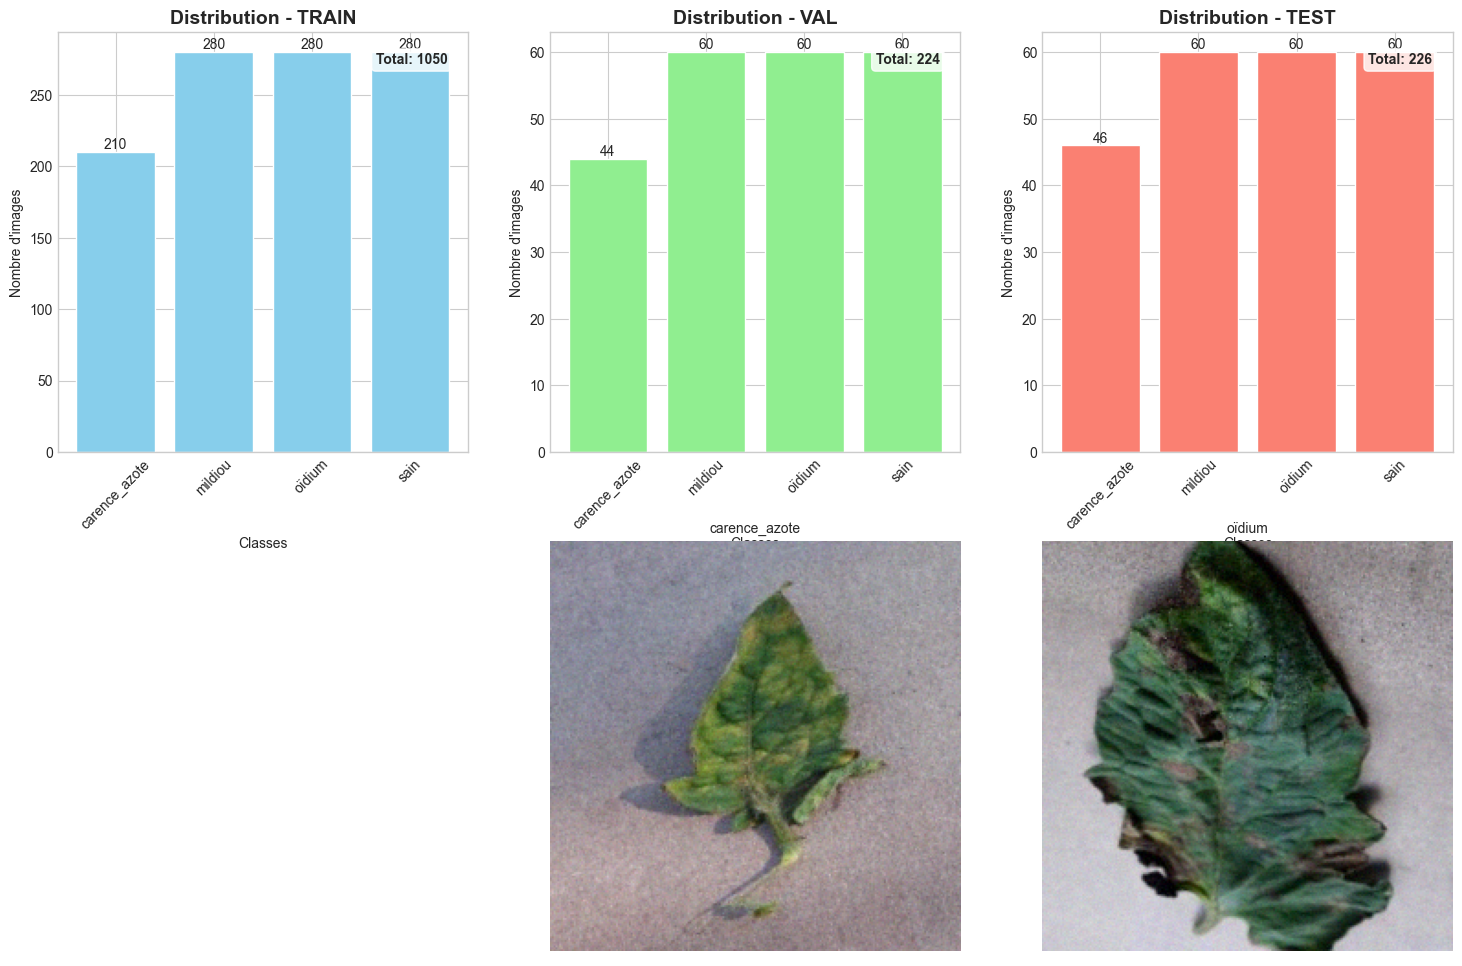

In [ ]:
# ==================== VISUALISATION EXPLORATOIRE DU DATASET ====================
# Cette fonction crée une visualisation complète en 6 graphiques pour analyser
# la distribution des données et vérifier la qualité des images après prétraitement.
# Elle combine analyse quantitative (statistiques) et qualitative (images échantillons).


def explore_dataset_visualization(dataset):
    """
    Visualise le dataset pour comprendre sa structure
    """
    print("🎨 Exploration visuelle du dataset...")

    # 1. Distribution des classes
    fig, axes = plt.subplots(2, 3, figsize=(18, 12))

    splits = ['train', 'val', 'test']
    colors = ['skyblue', 'lightgreen', 'salmon']

    for idx, (split, color) in enumerate(zip(splits, colors)):
        ax = axes[0, idx]
        y_data = dataset[split]['original_y']

        # Calculer la distribution
        unique, counts = np.unique(y_data, return_counts=True)
        class_counts = dict(zip([class_names[i] for i in unique], counts))

        # Bar plot
        bars = ax.bar(class_counts.keys(), class_counts.values(), color=color)
        ax.set_title(f'Distribution - {split.upper()}', fontsize=14, fontweight='bold')
        ax.set_xlabel('Classes')
        ax.set_ylabel('Nombre d\'images')
        ax.tick_params(axis='x', rotation=45)

        # Ajouter les valeurs
        for bar, count in zip(bars, class_counts.values()):
            height = bar.get_height()
            ax.text(bar.get_x() + bar.get_width()/2., height,
                   f'{count}', ha='center', va='bottom')

        # Ajouter le total
        ax.text(0.95, 0.95, f'Total: {len(y_data)}',
               transform=ax.transAxes, ha='right', va='top',
               fontweight='bold', bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

    # 2. Exemples d'images par classe
    print("\n📸 Affichage d'exemples d'images...")

    # Prendre un exemple de chaque classe
    n_samples = min(8, num_classes)
    sample_indices = []

    for class_idx in range(n_samples):
        class_indices = np.where(y_train == class_idx)[0]
        if len(class_indices) > 0:
            sample_indices.append(np.random.choice(class_indices))

    # Afficher les échantillons
    axes[1, 0].axis('off')  # Masquer la première cellule du bas

    for i, idx in enumerate(sample_indices):
        ax = axes[1, i+1] if i < 2 else axes[1, i]
        img = X_train[idx]
        label_idx = y_train[idx]

        # Dé-normaliser si nécessaire (pour ImageNet normalization)
        img_display = img.copy()
        if img_display.min() < 0:  # Normalisation ImageNet
            img_display = (img_display * [0.229, 0.224, 0.225]) + [0.485, 0.456, 0.406]
            img_display = np.clip(img_display, 0, 1)

        ax.imshow(img_display)
        ax.set_title(f'{class_names[label_idx]}', fontsize=10)
        ax.axis('off')

    # Masquer les cellules vides
    for i in range(len(sample_indices), 6):
        axes[1, i].axis('off')

    plt.suptitle('EXPLORATION DU DATASET POUR TRANSFER LEARNING',
                 fontsize=16, fontweight='bold', y=1.02)
    plt.tight_layout()

    # Sauvegarder la visualisation
    save_path = RESULTS_DIR / 'dataset_exploration.png'
    plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()

    print(f"📊 Visualisation sauvegardée: {save_path}")

    # 3. Statistiques détaillées
    print("\n📈 Statistiques détaillées:")
    print("-" * 40)

    for split in splits:
        X_data = dataset[split]['X']
        y_data = dataset[split]['original_y']

        print(f"\n{split.upper()}:")
        print(f"  Nombre total: {len(X_data)}")
        print(f"  Shape images: {X_data.shape[1:]}")
        print(f"  Valeurs min/max: {X_data.min():.3f}/{X_data.max():.3f}")
        print(f"  Moyenne/std: {X_data.mean():.3f}/{X_data.std():.3f}")

        # Distribution par classe
        unique, counts = np.unique(y_data, return_counts=True)
        print(f"  Distribution:")
        for cls, count in zip(unique, counts):
            percentage = count / len(y_data) * 100
            print(f"    {class_names[cls]}: {count} ({percentage:.1f}%)")

# %%
# Exploration du dataset
explore_dataset_visualization(dataset)

4. Construction du Modèle avec Transfer Learning


In [ ]:
# ==================== CONSTRUCTION DU MODÈLE DE TRANSFER LEARNING ====================
# Cette fonction implémente la stratégie complète de transfer learning avec MobileNetV2.
# Elle suit une approche en deux phases : d'abord entraîner les nouvelles couches avec
# la base gelée, puis fine-tuner les dernières couches du modèle pré-entraîné.


def build_transfer_learning_model(input_shape=(224, 224, 3), num_classes=4,
                                 freeze_base=True, fine_tune_layers=0):
    """
    Construit un modèle de transfer learning avec MobileNetV2

    Args:
        input_shape: Shape des images d'entrée
        num_classes: Nombre de classes de sortie
        freeze_base: Si True, gèle les couches de base
        fine_tune_layers: Nombre de couches à fine-tuner (si > 0)

    Returns:
        Modèle Keras compilé
    """
    print("🏗️ Construction du modèle MobileNetV2...")
    print(f"  Input shape: {input_shape}")
    print(f"  Nombre de classes: {num_classes}")
    print(f"  Freeze base: {freeze_base}")
    print(f"  Fine-tune layers: {fine_tune_layers}")

    # ==================== ÉTAPE 1 : CHARGER LE MODÈLE DE BASE ====================
    print("\n1. Chargement de MobileNetV2 pré-entraîné...")

    # MobileNetV2 pré-entraîné sur ImageNet (sans les couches fully connected)
    base_model = MobileNetV2(
        weights='imagenet',
        include_top=False,           # Exclure les couches de classification
        input_shape=input_shape,
        pooling=None,                # Nous ajouterons notre propre pooling
        alpha=1.0                    # Version standard (1.0) vs light (0.35, 0.5, 0.75, 1.0, 1.3, 1.4)
    )

    # Informations sur le modèle de base
    print(f"  ✅ MobileNetV2 chargé")
    print(f"  Nombre de couches: {len(base_model.layers)}")
    print(f"  Nombre de paramètres: {base_model.count_params():,}")

    # ==================== ÉTAPE 2 : CONGELER/DÉCONGELER LES COUCHES ====================
    print("\n2. Configuration du gel/dégel des couches...")

    if freeze_base:
        # Geler toutes les couches du modèle de base
        base_model.trainable = False
        print(f"  ✅ Toutes les couches de base gelées")
    else:
        # Dégeler certaines couches pour le fine-tuning
        base_model.trainable = True

        if fine_tune_layers > 0:
            # Geler toutes les couches sauf les N dernières
            for layer in base_model.layers[:-fine_tune_layers]:
                layer.trainable = False

            print(f"  ✅ {fine_tune_layers} dernières couches dégelées pour fine-tuning")
            print(f"  Nombre de couches entraînables: {sum([l.trainable for l in base_model.layers])}")
        else:
            print(f"  ✅ Toutes les couches dégelées")

    # ==================== ÉTAPE 3 : AJOUTER DES COUCHES PERSONNALISÉES ====================
    print("\n3. Ajout des couches personnalisées...")

    # Créer le modèle séquentiel
    model = models.Sequential(name='mobilenetv2_transfer')

    # Ajouter le modèle de base
    model.add(base_model)

    # Global Average Pooling (réduit la dimension spatiale)
    model.add(layers.GlobalAveragePooling2D(name='global_avg_pool'))
    model.add(layers.BatchNormalization(name='bn_1'))
    model.add(layers.Dropout(0.3, name='dropout_1'))

    # Couche dense intermédiaire
    model.add(layers.Dense(512, activation='relu', name='dense_1'))
    model.add(layers.BatchNormalization(name='bn_2'))
    model.add(layers.Dropout(0.4, name='dropout_2'))

    # Couche dense supplémentaire (optionnelle)
    model.add(layers.Dense(256, activation='relu', name='dense_2'))
    model.add(layers.BatchNormalization(name='bn_3'))
    model.add(layers.Dropout(0.5, name='dropout_3'))

    # Couche de sortie
    model.add(layers.Dense(num_classes, activation='softmax', name='output'))

    # ==================== ÉTAPE 4 : COMPILATION ====================
    print("\n4. Compilation du modèle...")

    # Configuration de l'optimizer avec learning rate adaptatif
    if freeze_base:
        # Pour l'entraînement initial, learning rate plus bas
        initial_lr = 0.001
    else:
        # Pour le fine-tuning, learning rate encore plus bas
        initial_lr = 0.0001

    optimizer = optimizers.Adam(
        learning_rate=initial_lr,
        beta_1=0.9,
        beta_2=0.999,
        epsilon=1e-07,
        amsgrad=False
    )

    # Compiler le modèle
    model.compile(
        optimizer=optimizer,
        loss='categorical_crossentropy',
        metrics=[
            'accuracy',
            metrics.Precision(name='precision'),
            metrics.Recall(name='recall'),
            metrics.AUC(name='auc', curve='ROC'),
            metrics.AUC(name='pr_auc', curve='PR')  # AUC Precision-Recall
        ]
    )

    # ==================== ÉTAPE 5 : RÉSUMÉ ET ANALYSE ====================
    print("\n5. Analyse du modèle construit...")
    model.summary()

    # Calculer les statistiques des paramètres
    total_params = model.count_params()
    trainable_params = sum([tf.keras.backend.count_params(w) for w in model.trainable_weights])
    non_trainable_params = total_params - trainable_params

    print(f"\n📊 Statistiques des paramètres:")
    print(f"  Total: {total_params:,}")
    print(f"  Entraînables: {trainable_params:,} ({trainable_params/total_params*100:.1f}%)")
    print(f"  Non-entraînables: {non_trainable_params:,} ({non_trainable_params/total_params*100:.1f}%)")

    # Visualiser l'architecture
    try:
        from tensorflow.keras.utils import plot_model
        plot_path = RESULTS_DIR / 'mobilenetv2_architecture.png'
        plot_model(model, to_file=str(plot_path), show_shapes=True, show_layer_names=True)
        print(f"\n🎨 Architecture sauvegardée: {plot_path}")
    except:
        print("\n⚠️  Impossible de générer le diagramme d'architecture")

    return model, base_model


# %%
# ==================== PHASE 1 : CONSTRUCTION DU MODÈLE AVEC BASE GELÉE ====================
# Crée la première version du modèle où toutes les couches de MobileNetV2 sont gelées.
# Seules les nouvelles couches ajoutées seront entraînées, ce qui préserve les
# connaissances acquises sur ImageNet tout en adaptant le modèle à notre problème.
# %%
# Construction du modèle initial (base gelée)
print("=" * 60)
print("PHASE 1 : MODÈLE AVEC BASE GELÉE")
print("=" * 60)

model_frozen, base_model = build_transfer_learning_model(
    input_shape=X_train.shape[1:],
    num_classes=num_classes,
    freeze_base=True,
    fine_tune_layers=0
)

PHASE 1 : MODÈLE AVEC BASE GELÉE
🏗️ Construction du modèle MobileNetV2...
  Input shape: (224, 224, 3)
  Nombre de classes: 4
  Freeze base: True
  Fine-tune layers: 0

1. Chargement de MobileNetV2 pré-entraîné...
  ✅ MobileNetV2 chargé
  Nombre de couches: 154
  Nombre de paramètres: 2,257,984

2. Configuration du gel/dégel des couches...
  ✅ Toutes les couches de base gelées

3. Ajout des couches personnalisées...

4. Compilation du modèle...

5. Analyse du modèle construit...


Model: "mobilenetv2_transfer"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_avg_pool                 │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn_1 (BatchNormalization)       │ (None, 1280)           │         5,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 512)            │       655,872 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn_2 (BatchNormalization)       │ (None, 512)            │         2,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn_3 (BatchNormalization)       │ (None, 256)            │         1,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,054,404 (11.65 MB)

 Trainable params: 792,324 (3.02 MB)

 Non-trainable params: 2,262,080 (8.63 MB)


📊 Statistiques des paramètres:
  Total: 3,054,404
  Entraînables: 792,324 (25.9%)
  Non-entraînables: 2,262,080 (74.1%)
You must install pydot (`pip install pydot`) for `plot_model` to work.

🎨 Architecture sauvegardée: C:\Users\Ridha\Downloads\agripredict\agripredict\results\transfer_learning\mobilenetv2_architecture.png


5. Configuration des Callbacks


In [ ]:
# ==================== CONFIGURATION DES CALLBACKS AVANCÉS ====================
# Cette fonction configure un ensemble sophistiqué de callbacks pour optimiser
# l'entraînement du modèle de transfer learning. Les callbacks automatisent des
# stratégies d'optimisation essentielles comme l'arrêt précoce, l'ajustement du
# learning rate, et le suivi détaillé des performances.

def setup_advanced_callbacks(model_name="mobilenetv2",
                            patience_early_stop=10,
                            patience_reduce_lr=5,
                            monitor_metric='val_loss'):
    """
    Configure des callbacks avancés pour l'entraînement

    Returns:
        Liste des callbacks configurés
    """
    print(f"🎛️ Configuration des callbacks avancés pour {model_name}...")

    callbacks_list = []

    # 1. CHECKPOINT POUR LE MEILLEUR MODÈLE
    checkpoint_path = MODELS_DIR / f"{model_name}_best.h5"
    checkpoint_callback = callbacks.ModelCheckpoint(
        filepath=str(checkpoint_path),
        monitor=monitor_metric,
        save_best_only=True,
        save_weights_only=False,
        mode='min' if 'loss' in monitor_metric else 'max',
        verbose=1
    )
    callbacks_list.append(checkpoint_callback)
    print(f"  ✅ ModelCheckpoint: {checkpoint_path.name}")

    # 2. EARLY STOPPING
    early_stopping = callbacks.EarlyStopping(
        monitor=monitor_metric,
        patience=patience_early_stop,
        restore_best_weights=True,
        verbose=1,
        mode='min' if 'loss' in monitor_metric else 'max'
    )
    callbacks_list.append(early_stopping)
    print(f"  ✅ EarlyStopping: patience={patience_early_stop}")

    # 3. REDUCE LEARNING RATE ON PLATEAU
    reduce_lr = callbacks.ReduceLROnPlateau(
        monitor=monitor_metric,
        factor=0.5,           # Réduire le LR de moitié
        patience=patience_reduce_lr,
        min_lr=1e-7,          # Learning rate minimum
        verbose=1,
        mode='min' if 'loss' in monitor_metric else 'max'
    )
    callbacks_list.append(reduce_lr)
    print(f"  ✅ ReduceLROnPlateau: factor=0.5, patience={patience_reduce_lr}")

    # 4. TENSORBOARD (pour le monitoring avancé)
    try:
        log_dir = RESULTS_DIR / "logs" / f"{model_name}_{datetime.now().strftime('%Y%m%d_%H%M%S')}"
        tensorboard_callback = callbacks.TensorBoard(
            log_dir=str(log_dir),
            histogram_freq=1,
            write_graph=True,
            write_images=False,
            update_freq='epoch'
        )
        callbacks_list.append(tensorboard_callback)
        print(f"  ✅ TensorBoard: {log_dir}")
    except:
        print("  ⚠️  TensorBoard non disponible")

    # 5. CSV LOGGER
    csv_logger = callbacks.CSVLogger(
        filename=str(RESULTS_DIR / f"{model_name}_training_log.csv"),
        separator=',',
        append=False
    )
    callbacks_list.append(csv_logger)
    print(f"  ✅ CSVLogger: {model_name}_training_log.csv")

    # 6. LEARNING RATE SCHEDULER (optionnel - échelonné)
    def lr_schedule(epoch):
        """Schedule de learning rate personnalisé"""
        initial_lr = 0.001
        if epoch < 5:
            return initial_lr
        elif epoch < 10:
            return initial_lr * 0.5
        elif epoch < 15:
            return initial_lr * 0.2
        else:
            return initial_lr * 0.1

    lr_scheduler = callbacks.LearningRateScheduler(lr_schedule, verbose=1)
    callbacks_list.append(lr_scheduler)
    print(f"  ✅ LearningRateScheduler: schedule personnalisé")

    print(f"\n🎯 Total callbacks: {len(callbacks_list)}")
    return callbacks_list

# %%
# ==================== CONFIGURATION DES CALLBACKS POUR LA PHASE 1 ====================
# Configure les callbacks spécifiques pour la première phase d'entraînement
# où la base de MobileNetV2 est gelée. Des paramètres adaptés sont utilisés
# pour cette phase d'adaptation initiale.
# %%
# Configuration des callbacks pour la phase 1 (base gelée)
callbacks_frozen = setup_advanced_callbacks(
    model_name="mobilenetv2_frozen",
    patience_early_stop=10,
    patience_reduce_lr=5,
    monitor_metric='val_loss'
)

🎛️ Configuration des callbacks avancés pour mobilenetv2_frozen...
  ✅ ModelCheckpoint: mobilenetv2_frozen_best.h5
  ✅ EarlyStopping: patience=10
  ✅ ReduceLROnPlateau: factor=0.5, patience=5
  ✅ TensorBoard: C:\Users\Ridha\Downloads\agripredict\agripredict\results\transfer_learning\logs\mobilenetv2_frozen_20251207_172124
  ✅ CSVLogger: mobilenetv2_frozen_training_log.csv
  ✅ LearningRateScheduler: schedule personnalisé

🎯 Total callbacks: 6


6. Phase 1 : Entraînement avec Base Gelée

PHASE 1 : ENTRAÎNEMENT AVEC BASE GELÉE

🚀 Phase 1 - Base Gelée - Début de l'entraînement...
📊 Configuration:
  Epochs: 30
  Batch size: 32
  Train samples: 1050
  Val samples: 224
  Class weights: {0: np.float64(1.25), 1: np.float64(0.9375), 2: np.float64(0.9375), 3: np.float64(0.9375)}

Epoch 1: LearningRateScheduler setting learning rate to 0.001.
Epoch 1/30
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 209ms/step - accuracy: 0.5907 - auc: 0.8083 - loss: 1.2595 - pr_auc: 0.6486 - precision: 0.6114 - recall: 0.5529
Epoch 1: val_loss improved from None to 0.37427, saving model to C:\Users\Ridha\Downloads\agripredict\agripredict\notebooks\backend\models\mobilenetv2_frozen_best.h5


33/33 ━━━━━━━━━━━━━━━━━━━━ 14s 319ms/step - accuracy: 0.7343 - auc: 0.9176 - loss: 0.7793 - pr_auc: 0.8197 - precision: 0.7553 - recall: 0.7143 - val_accuracy: 0.9018 - val_auc: 0.9790 - val_loss: 0.3743 - val_pr_auc: 0.9449 - val_precision: 0.9327 - val_recall: 0.8661 - learning_rate: 0.0010

Epoch 2: LearningRateScheduler setting learning rate to 0.001.
Epoch 2/30
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 210ms/step - accuracy: 0.9144 - auc: 0.9894 - loss: 0.2318 - pr_auc: 0.9732 - precision: 0.9163 - recall: 0.9098
Epoch 2: val_loss did not improve from 0.37427
33/33 ━━━━━━━━━━━━━━━━━━━━ 9s 286ms/step - accuracy: 0.9095 - auc: 0.9892 - loss: 0.2348 - pr_auc: 0.9714 - precision: 0.9118 - recall: 0.9057 - val_accuracy: 0.8393 - val_auc: 0.9662 - val_loss: 0.4325 - val_pr_auc: 0.9060 - val_precision: 0.8491 - val_recall: 0.8036 - learning_rate: 0.0010

Epoch 3: LearningRateScheduler setting learning rate to 0.001.
Epoch 3/30
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 204ms/step - accuracy: 0.9153 - auc: 0.9908

33/33 ━━━━━━━━━━━━━━━━━━━━ 9s 289ms/step - accuracy: 0.9505 - auc: 0.9953 - loss: 0.1414 - pr_auc: 0.9870 - precision: 0.9520 - recall: 0.9448 - val_accuracy: 0.8839 - val_auc: 0.9866 - val_loss: 0.2717 - val_pr_auc: 0.9626 - val_precision: 0.8991 - val_recall: 0.8750 - learning_rate: 0.0010

Epoch 5: LearningRateScheduler setting learning rate to 0.001.
Epoch 5/30
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 199ms/step - accuracy: 0.9703 - auc: 0.9984 - loss: 0.0896 - pr_auc: 0.9954 - precision: 0.9715 - recall: 0.9697
Epoch 5: val_loss did not improve from 0.27169
33/33 ━━━━━━━━━━━━━━━━━━━━ 9s 274ms/step - accuracy: 0.9638 - auc: 0.9982 - loss: 0.0986 - pr_auc: 0.9948 - precision: 0.9656 - recall: 0.9619 - val_accuracy: 0.8393 - val_auc: 0.9775 - val_loss: 0.3436 - val_pr_auc: 0.9364 - val_precision: 0.8378 - val_recall: 0.8304 - learning_rate: 0.0010

Epoch 6: LearningRateScheduler setting learning rate to 0.0005.
Epoch 6/30
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 195ms/step - accuracy: 0.9715 - auc: 0.9989

33/33 ━━━━━━━━━━━━━━━━━━━━ 9s 272ms/step - accuracy: 0.9800 - auc: 0.9995 - loss: 0.0545 - pr_auc: 0.9985 - precision: 0.9809 - recall: 0.9800 - val_accuracy: 0.9107 - val_auc: 0.9916 - val_loss: 0.2101 - val_pr_auc: 0.9761 - val_precision: 0.9107 - val_recall: 0.9107 - learning_rate: 5.0000e-04

Epoch 8: LearningRateScheduler setting learning rate to 0.0005.
Epoch 8/30
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 209ms/step - accuracy: 0.9876 - auc: 0.9997 - loss: 0.0393 - pr_auc: 0.9992 - precision: 0.9918 - recall: 0.9876
Epoch 8: val_loss improved from 0.21013 to 0.20211, saving model to C:\Users\Ridha\Downloads\agripredict\agripredict\notebooks\backend\models\mobilenetv2_frozen_best.h5


33/33 ━━━━━━━━━━━━━━━━━━━━ 9s 286ms/step - accuracy: 0.9829 - auc: 0.9995 - loss: 0.0491 - pr_auc: 0.9987 - precision: 0.9847 - recall: 0.9829 - val_accuracy: 0.9196 - val_auc: 0.9920 - val_loss: 0.2021 - val_pr_auc: 0.9774 - val_precision: 0.9189 - val_recall: 0.9107 - learning_rate: 5.0000e-04

Epoch 9: LearningRateScheduler setting learning rate to 0.0005.
Epoch 9/30
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 205ms/step - accuracy: 0.9669 - auc: 0.9977 - loss: 0.0817 - pr_auc: 0.9939 - precision: 0.9706 - recall: 0.9669
Epoch 9: val_loss did not improve from 0.20211
33/33 ━━━━━━━━━━━━━━━━━━━━ 9s 282ms/step - accuracy: 0.9733 - auc: 0.9986 - loss: 0.0667 - pr_auc: 0.9962 - precision: 0.9743 - recall: 0.9733 - val_accuracy: 0.8750 - val_auc: 0.9881 - val_loss: 0.2638 - val_pr_auc: 0.9667 - val_precision: 0.8739 - val_recall: 0.8661 - learning_rate: 5.0000e-04

Epoch 10: LearningRateScheduler setting learning rate to 0.0005.
Epoch 10/30
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 210ms/step - accuracy: 0.9808 - 

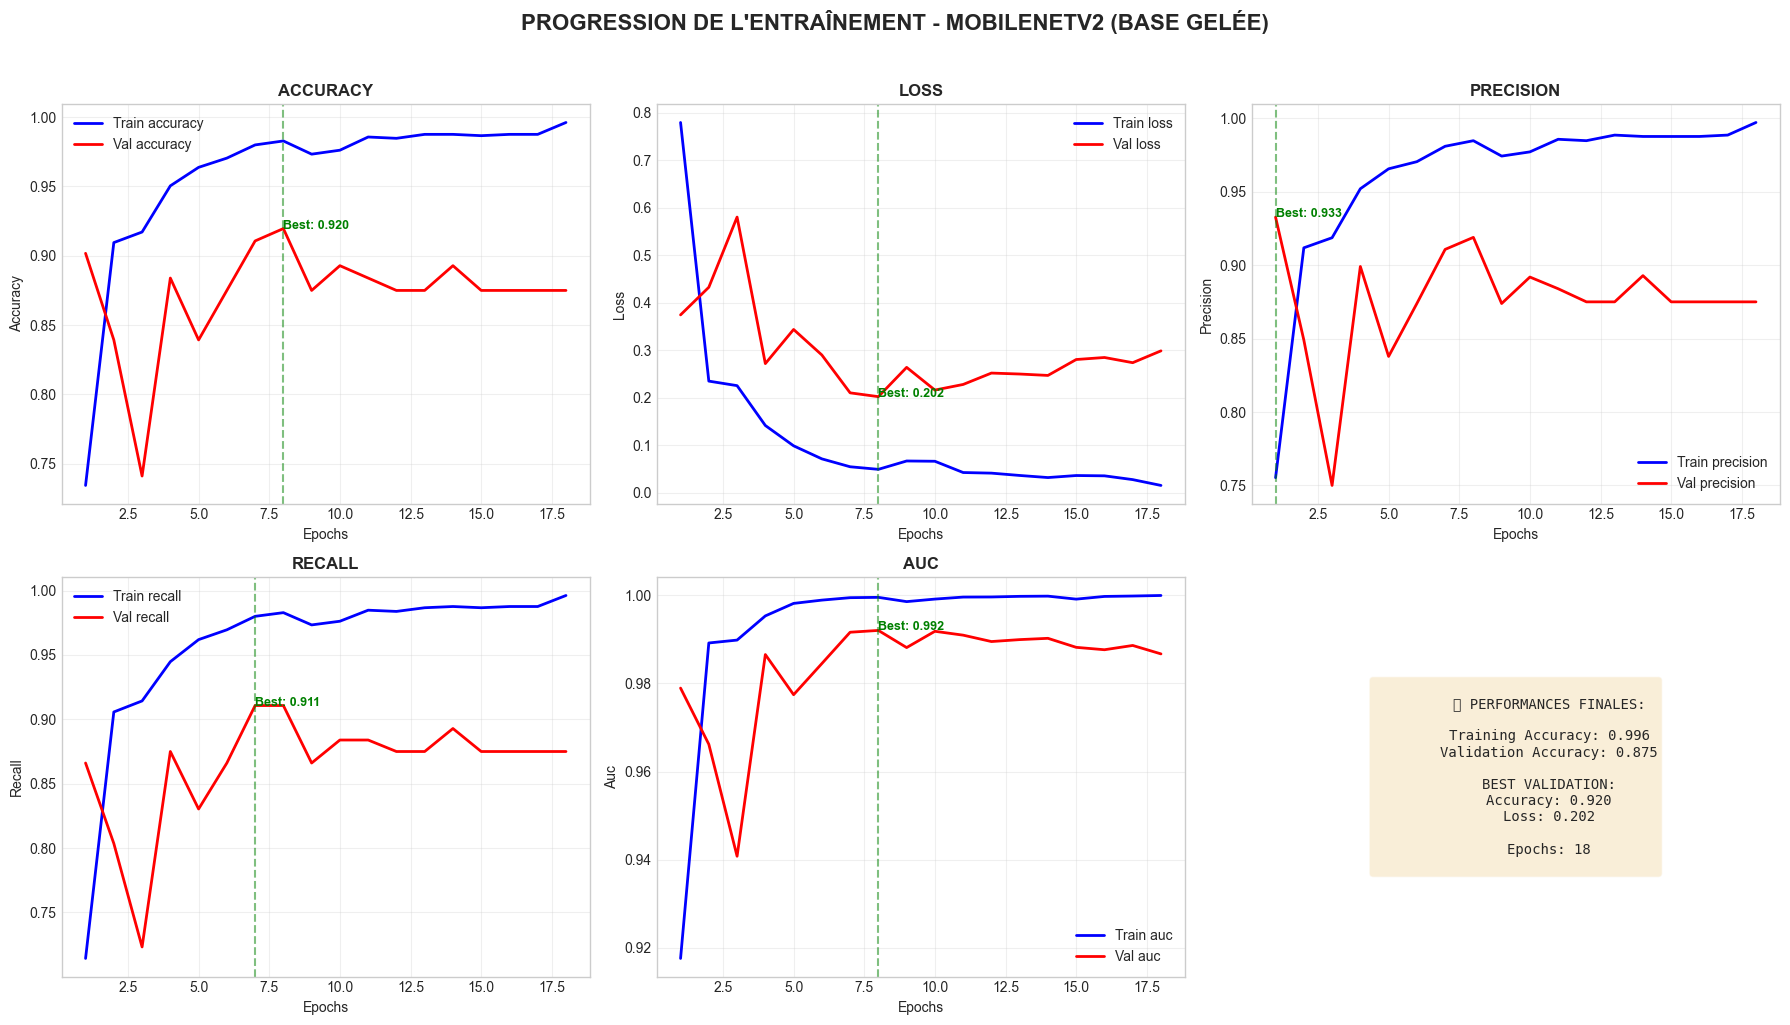


📊 Meilleures métriques - Phase 1:
  Best Val Accuracy: 0.9196
  Best Val Loss: 0.2021
  Best Epoch (Acc): 8
  Final Val Accuracy: 0.8750


In [ ]:
# ==================== FONCTION D'ENTRAÎNEMENT DU MODÈLE DE TRANSFER LEARNING ====================
# Cette fonction encapsule le processus complet d'entraînement avec gestion du temps,
# suivi des performances, et application des stratégies d'optimisation configurées
# via les callbacks. Elle est réutilisable pour les deux phases d'entraînement.


def train_transfer_model(model, X_train, y_train, X_val, y_val,
                        class_weights=None, epochs=30, batch_size=32,
                        callbacks_list=None, phase_name="Phase 1"):
    """
    Entraîne un modèle de transfer learning

    Returns:
        history: Historique d'entraînement
        training_time: Temps d'entraînement
    """
    print(f"\n🚀 {phase_name} - Début de l'entraînement...")
    print("=" * 60)

    print(f"📊 Configuration:")
    print(f"  Epochs: {epochs}")
    print(f"  Batch size: {batch_size}")
    print(f"  Train samples: {X_train.shape[0]}")
    print(f"  Val samples: {X_val.shape[0]}")

    if class_weights:
        print(f"  Class weights: {class_weights}")

    # Mesurer le temps
    start_time = time.time()

    # Entraînement
    history = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=epochs,
        batch_size=batch_size,
        class_weight=class_weights,
        callbacks=callbacks_list if callbacks_list else [],
        verbose=1,
        shuffle=True
    )

    # Calcul du temps
    training_time = time.time() - start_time
    hours = int(training_time // 3600)
    minutes = int((training_time % 3600) // 60)
    seconds = int(training_time % 60)

    print(f"\n✅ {phase_name} terminée en {hours:02d}:{minutes:02d}:{seconds:02d}")

    return history, training_time

# %%
# %%
# ==================== PHASE 1 : ENTRAÎNEMENT AVEC BASE GELÉE ====================
# Exécute la première phase d'entraînement où seules les nouvelles couches
# ajoutées à MobileNetV2 sont entraînées, tandis que la base pré-entraînée
# reste figée. Cette phase adapte le modèle à notre tâche spécifique.
# Entraînement de la phase 1 (base gelée)
print("=" * 60)
print("PHASE 1 : ENTRAÎNEMENT AVEC BASE GELÉE")
print("=" * 60)

history_frozen, time_frozen = train_transfer_model(
    model=model_frozen,
    X_train=X_train,
    y_train=y_train_onehot,
    X_val=X_val,
    y_val=y_val_onehot,
    class_weights=class_weights,
    epochs=30,  # Plus d'epochs car moins de paramètres entraînables
    batch_size=32,
    callbacks_list=callbacks_frozen,
    phase_name="Phase 1 - Base Gelée"
)

# %%
# ==================== VISUALISATION DE LA PROGRESSION D'ENTRAÎNEMENT ====================
# Crée un dashboard complet de 6 graphiques pour analyser l'évolution des métriques
# pendant l'entraînement. Cette visualisation est cruciale pour diagnostiquer
# les problèmes comme le surapprentissage et optimiser les hyperparamètres.
def plot_training_progress(history, model_name="Model", save_path=None):
    """
    Visualise la progression de l'entraînement
    """
    print(f"\n📈 Visualisation de l'entraînement - {model_name}")

    # Extraire les métriques
    metrics_to_plot = ['accuracy', 'loss', 'precision', 'recall', 'auc']

    # Créer la figure
    fig, axes = plt.subplots(2, 3, figsize=(18, 10))
    axes = axes.flatten()

    epochs = range(1, len(history.history['accuracy']) + 1)

    for idx, metric in enumerate(metrics_to_plot):
        ax = axes[idx]

        # Training metric
        if metric in history.history:
            train_values = history.history[metric]
            ax.plot(epochs, train_values, 'b-', label=f'Train {metric}', linewidth=2)

        # Validation metric
        val_metric = f'val_{metric}'
        if val_metric in history.history:
            val_values = history.history[val_metric]
            ax.plot(epochs, val_values, 'r-', label=f'Val {metric}', linewidth=2)

        ax.set_title(f'{metric.upper()}', fontsize=12, fontweight='bold')
        ax.set_xlabel('Epochs')
        ax.set_ylabel(metric.capitalize())
        ax.legend()
        ax.grid(True, alpha=0.3)

        # Ajouter la meilleure valeur
        if val_metric in history.history:
            best_epoch = np.argmax(val_values) if metric != 'loss' else np.argmin(val_values)
            best_value = val_values[best_epoch]
            ax.axvline(x=best_epoch+1, color='g', linestyle='--', alpha=0.5)
            ax.text(best_epoch+1, best_value, f'Best: {best_value:.3f}',
                   color='green', fontweight='bold', fontsize=9)

    # Learning rate (si disponible)
    ax = axes[5]
    if 'lr' in history.history:
        lr_values = history.history['lr']
        ax.plot(epochs, lr_values, 'g-', linewidth=2, marker='o')
        ax.set_title('LEARNING RATE', fontsize=12, fontweight='bold')
        ax.set_xlabel('Epochs')
        ax.set_ylabel('Learning Rate')
        ax.set_yscale('log')
        ax.grid(True, alpha=0.3)
    else:
        # Afficher un résumé des performances
        final_train_acc = history.history['accuracy'][-1]
        final_val_acc = history.history['val_accuracy'][-1]
        best_val_acc = np.max(history.history['val_accuracy'])
        best_val_loss = np.min(history.history['val_loss'])

        summary_text = f"""
        📊 PERFORMANCES FINALES:

        Training Accuracy: {final_train_acc:.3f}
        Validation Accuracy: {final_val_acc:.3f}

        BEST VALIDATION:
        Accuracy: {best_val_acc:.3f}
        Loss: {best_val_loss:.3f}

        Epochs: {len(epochs)}
        """

        ax.text(0.5, 0.5, summary_text,
               ha='center', va='center', transform=ax.transAxes,
               fontsize=10, fontfamily='monospace',
               bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))
        ax.axis('off')

    plt.suptitle(f'PROGRESSION DE L\'ENTRAÎNEMENT - {model_name.upper()}',
                 fontsize=16, fontweight='bold', y=1.02)
    plt.tight_layout()

    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
        print(f"  📸 Graphique sauvegardé: {save_path}")

    plt.show()

    # Retourner les meilleures métriques
    best_metrics = {
        'best_val_accuracy': np.max(history.history['val_accuracy']),
        'best_val_loss': np.min(history.history['val_loss']),
        'best_epoch_acc': np.argmax(history.history['val_accuracy']) + 1,
        'best_epoch_loss': np.argmin(history.history['val_loss']) + 1,
        'final_val_accuracy': history.history['val_accuracy'][-1]
    }

    return best_metrics

# %%
# ==================== VISUALISATION DES RÉSULTATS DE LA PHASE 1 ====================
# Génère et sauvegarde les graphiques de progression pour la phase d'entraînement
# avec base gelée, et affiche un résumé des meilleures performances obtenues.

save_path_frozen = RESULTS_DIR / 'training_progress_frozen.png'
best_metrics_frozen = plot_training_progress(history_frozen,
                                            "MobileNetV2 (Base Gelée)",
                                            save_path_frozen)

print(f"\n📊 Meilleures métriques - Phase 1:")
print(f"  Best Val Accuracy: {best_metrics_frozen['best_val_accuracy']:.4f}")
print(f"  Best Val Loss: {best_metrics_frozen['best_val_loss']:.4f}")
print(f"  Best Epoch (Acc): {best_metrics_frozen['best_epoch_acc']}")
print(f"  Final Val Accuracy: {best_metrics_frozen['final_val_accuracy']:.4f}")

7. Phase 2 : Fine-Tuning

PHASE 2 : PRÉPARATION DU FINE-TUNING

🔧 Préparation du fine-tuning...
  Nombre de couches à fine-tuner: 30

🔄 Recompilation avec learning rate réduit...
✅ Fine-tuning configuré:
  Couches totales: 154
  Couches entraînables: 30
  Couches gelées: 124
  Nouveau learning rate: 0.0001
🎛️ Configuration des callbacks avancés pour mobilenetv2_finetune...
  ✅ ModelCheckpoint: mobilenetv2_finetune_best.h5
  ✅ EarlyStopping: patience=8
  ✅ ReduceLROnPlateau: factor=0.5, patience=3
  ✅ TensorBoard: C:\Users\Ridha\Downloads\agripredict\agripredict\results\transfer_learning\logs\mobilenetv2_finetune_20251207_172611
  ✅ CSVLogger: mobilenetv2_finetune_training_log.csv
  ✅ LearningRateScheduler: schedule personnalisé

🎯 Total callbacks: 6
PHASE 2 : FINE-TUNING

🚀 Phase 2 - Fine-Tuning - Début de l'entraînement...
📊 Configuration:
  Epochs: 20
  Batch size: 32
  Train samples: 1050
  Val samples: 224
  Class weights: {0: np.float64(1.25), 1: np.float64(0.9375), 2: np.float64(0.9375), 3: np.float64(0.9

33/33 ━━━━━━━━━━━━━━━━━━━━ 18s 373ms/step - accuracy: 0.8971 - auc: 0.9787 - loss: 0.3772 - precision: 0.8985 - recall: 0.8933 - val_accuracy: 0.7500 - val_auc: 0.8977 - val_loss: 1.7125 - val_precision: 0.7545 - val_recall: 0.7411 - learning_rate: 0.0010

Epoch 2: LearningRateScheduler setting learning rate to 0.001.
Epoch 2/20
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 261ms/step - accuracy: 0.9604 - auc: 0.9936 - loss: 0.1349 - precision: 0.9604 - recall: 0.9596
Epoch 2: val_loss did not improve from 1.71247
33/33 ━━━━━━━━━━━━━━━━━━━━ 11s 338ms/step - accuracy: 0.9514 - auc: 0.9907 - loss: 0.1786 - precision: 0.9513 - recall: 0.9486 - val_accuracy: 0.6071 - val_auc: 0.7871 - val_loss: 4.3285 - val_precision: 0.6071 - val_recall: 0.6071 - learning_rate: 0.0010

Epoch 3: LearningRateScheduler setting learning rate to 0.001.
Epoch 3/20
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 258ms/step - accuracy: 0.9700 - auc: 0.9987 - loss: 0.0773 - precision: 0.9734 - recall: 0.9658
Epoch 3: val_loss did not improve from 

33/33 ━━━━━━━━━━━━━━━━━━━━ 11s 340ms/step - accuracy: 0.9848 - auc: 0.9998 - loss: 0.0345 - precision: 0.9847 - recall: 0.9838 - val_accuracy: 0.8125 - val_auc: 0.9242 - val_loss: 1.2196 - val_precision: 0.8125 - val_recall: 0.8125 - learning_rate: 0.0010

Epoch 5: LearningRateScheduler setting learning rate to 0.001.
Epoch 5/20
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 261ms/step - accuracy: 0.9930 - auc: 0.9991 - loss: 0.0365 - precision: 0.9930 - recall: 0.9926
Epoch 5: val_loss improved from 1.21965 to 0.56511, saving model to C:\Users\Ridha\Downloads\agripredict\agripredict\notebooks\backend\models\mobilenetv2_finetune_best.h5


33/33 ━━━━━━━━━━━━━━━━━━━━ 11s 344ms/step - accuracy: 0.9905 - auc: 0.9991 - loss: 0.0404 - precision: 0.9905 - recall: 0.9895 - val_accuracy: 0.8661 - val_auc: 0.9648 - val_loss: 0.5651 - val_precision: 0.8661 - val_recall: 0.8661 - learning_rate: 0.0010

Epoch 6: LearningRateScheduler setting learning rate to 0.0005.
Epoch 6/20
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 266ms/step - accuracy: 0.9884 - auc: 0.9998 - loss: 0.0324 - precision: 0.9887 - recall: 0.9881
Epoch 6: val_loss did not improve from 0.56511
33/33 ━━━━━━━━━━━━━━━━━━━━ 11s 342ms/step - accuracy: 0.9914 - auc: 0.9998 - loss: 0.0279 - precision: 0.9924 - recall: 0.9905 - val_accuracy: 0.7500 - val_auc: 0.9196 - val_loss: 1.2077 - val_precision: 0.7568 - val_recall: 0.7500 - learning_rate: 5.0000e-04

Epoch 7: LearningRateScheduler setting learning rate to 0.0005.
Epoch 7/20
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 272ms/step - accuracy: 0.9975 - auc: 1.0000 - loss: 0.0083 - precision: 0.9975 - recall: 0.9975
Epoch 7: val_loss did not improve

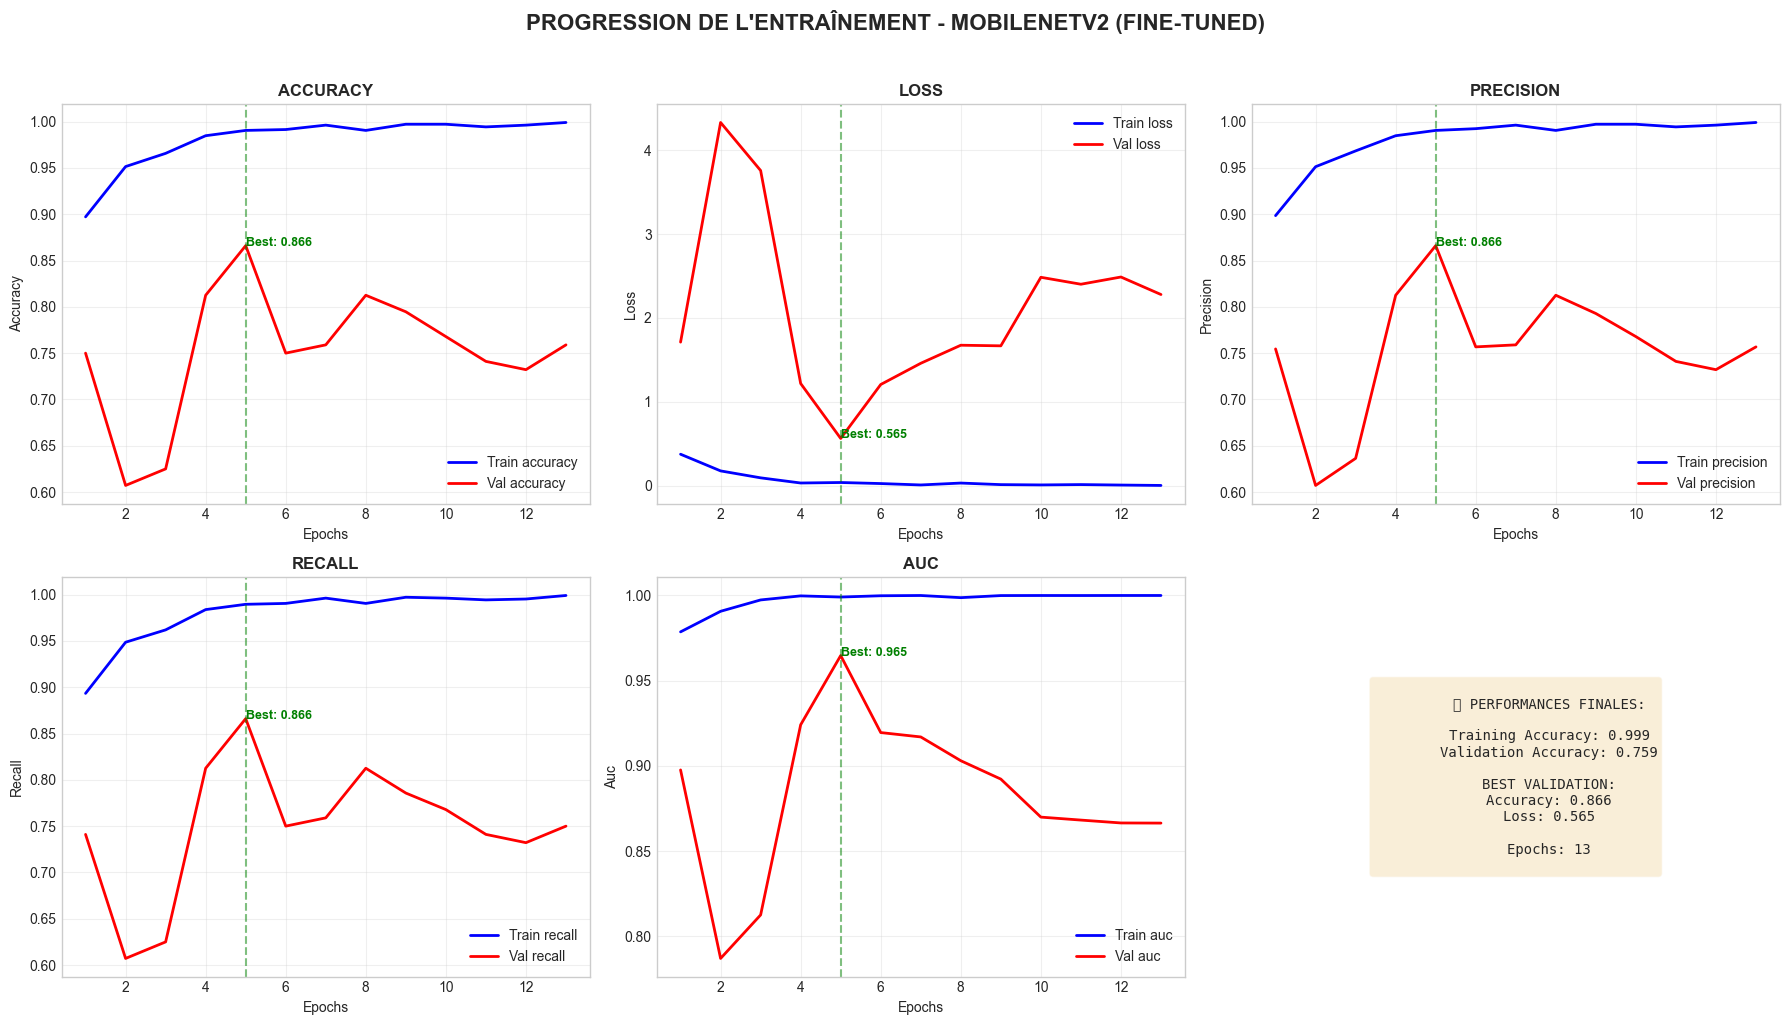


📊 Meilleures métriques - Phase 2:
  Best Val Accuracy: 0.8661
  Best Val Loss: 0.5651
  Improvement from frozen: -0.0536


In [ ]:
# ==================== FONCTION DE FINE-TUNING DU MODÈLE ====================
# Cette fonction implémente la seconde phase de l'approche de transfer learning :
# le dégel sélectif des dernières couches de MobileNetV2 pour un ajustement fin
# (fine-tuning) sur notre dataset spécifique de maladies de plantes.

def unfreeze_and_fine_tune(base_model, model, fine_tune_layers=30):
    """
    Dégèle les dernières couches pour le fine-tuning

    Args:
        base_model: Modèle de base MobileNetV2
        model: Modèle complet
        fine_tune_layers: Nombre de couches à fine-tuner
    """
    print(f"\n🔧 Préparation du fine-tuning...")
    print(f"  Nombre de couches à fine-tuner: {fine_tune_layers}")

    # 1. Dégeler le modèle de base
    base_model.trainable = True

    # 2. Geler toutes les couches sauf les N dernières
    total_layers = len(base_model.layers)

    for i, layer in enumerate(base_model.layers):
        if i < total_layers - fine_tune_layers:
            layer.trainable = False
        else:
            layer.trainable = True

    # 3. Compiler avec un learning rate plus faible
    print(f"\n🔄 Recompilation avec learning rate réduit...")

    # Learning rate plus faible pour le fine-tuning
    optimizer = optimizers.Adam(
        learning_rate=0.0001,  # 10x plus faible que l'initial
        beta_1=0.9,
        beta_2=0.999
    )

    model.compile(
        optimizer=optimizer,
        loss='categorical_crossentropy',
        metrics=[
            'accuracy',
            metrics.Precision(name='precision'),
            metrics.Recall(name='recall'),
            metrics.AUC(name='auc')
        ]
    )

    # 4. Afficher les statistiques
    trainable_count = np.sum([layer.trainable for layer in base_model.layers])
    print(f"✅ Fine-tuning configuré:")
    print(f"  Couches totales: {total_layers}")
    print(f"  Couches entraînables: {trainable_count}")
    print(f"  Couches gelées: {total_layers - trainable_count}")
    print(f"  Nouveau learning rate: 0.0001")

    return model

# %%
# ==================== PHASE 2 : PRÉPARATION DU FINE-TUNING ====================
# Prépare le modèle pour la seconde phase d'entraînement en dégelant
# sélectivement les 30 dernières couches de MobileNetV2, qui contiennent
# les features les plus spécifiques à notre tâche.

# Préparation du fine-tuning
print("=" * 60)
print("PHASE 2 : PRÉPARATION DU FINE-TUNING")
print("=" * 60)

# Dégeler les 30 dernières couches
model_finetune = unfreeze_and_fine_tune(base_model, model_frozen, fine_tune_layers=30)


# %%
# ==================== CONFIGURATION DES CALLBACKS POUR LE FINE-TUNING ====================
# Configure des callbacks adaptés à la phase de fine-tuning avec des paramètres
# plus stricts (moins de patience) car le modèle est déjà partiellement entraîné
# et devrait converger plus rapidement.

# %%
# Configuration des callbacks pour le fine-tuning
callbacks_finetune = setup_advanced_callbacks(
    model_name="mobilenetv2_finetune",
    patience_early_stop=8,  # Moins patient pour le fine-tuning
    patience_reduce_lr=3,
    monitor_metric='val_loss'
)

# %%
# ==================== PHASE 2 : ENTRAÎNEMENT DU FINE-TUNING ====================
# Exécute la seconde phase d'entraînement où les dernières couches de MobileNetV2
# sont ajustées pour mieux reconnaître les spécificités des maladies de plantes,
# tout en préservant les connaissances générales acquises sur ImageNet.

# %%
# Entraînement du fine-tuning
print("=" * 60)
print("PHASE 2 : FINE-TUNING")
print("=" * 60)

history_finetune, time_finetune = train_transfer_model(
    model=model_finetune,
    X_train=X_train,
    y_train=y_train_onehot,
    X_val=X_val,
    y_val=y_val_onehot,
    class_weights=class_weights,
    epochs=20,  # Moins d'epochs pour le fine-tuning
    batch_size=32,
    callbacks_list=callbacks_finetune,
    phase_name="Phase 2 - Fine-Tuning"
)
# %%
# ==================== VISUALISATION DES RÉSULTATS DU FINE-TUNING ====================
# Génère les graphiques de progression pour la phase de fine-tuning et calcule
# l'amélioration des performances par rapport à la phase avec base gelée.

# %%
# Visualiser le fine-tuning
save_path_finetune = RESULTS_DIR / 'training_progress_finetune.png'
best_metrics_finetune = plot_training_progress(history_finetune,
                                              "MobileNetV2 (Fine-Tuned)",
                                              save_path_finetune)

print(f"\n📊 Meilleures métriques - Phase 2:")
print(f"  Best Val Accuracy: {best_metrics_finetune['best_val_accuracy']:.4f}")
print(f"  Best Val Loss: {best_metrics_finetune['best_val_loss']:.4f}")
print(f"  Improvement from frozen: "
      f"{best_metrics_finetune['best_val_accuracy'] - best_metrics_frozen['best_val_accuracy']:.4f}")

8. Évaluation et Comparaison

ÉVALUATION DU MODÈLE FINE-TUNÉ

🧪 ÉVALUATION COMPLÈTE - MobileNetV2 Fine-Tuned
1. Génération des prédictions...
8/8 ━━━━━━━━━━━━━━━━━━━━ 3s 264ms/step

2. Calcul des métriques...

📊 Métriques principales:
  loss: 0.5941
  compile_metrics: 0.8761

3. Rapport de classification...

4. Matrice de confusion...


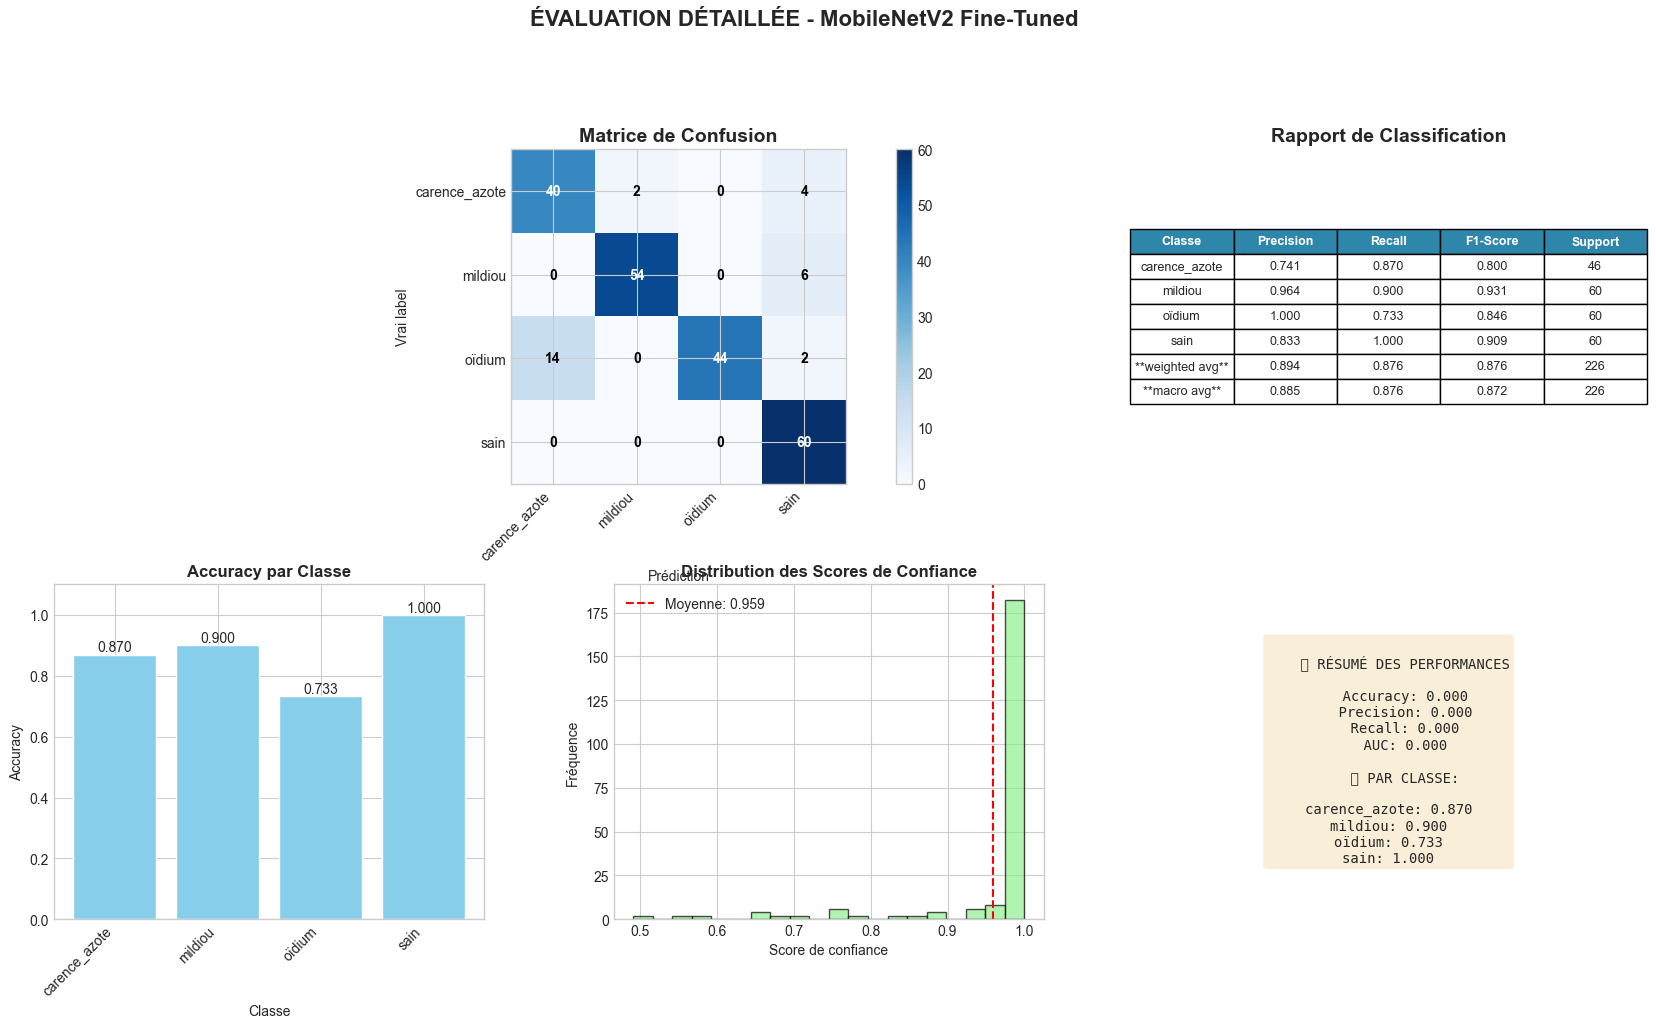


📸 Graphique sauvegardé: C:\Users\Ridha\Downloads\agripredict\agripredict\results\transfer_learning\evaluation_mobilenetv2_fine-tuned.png

📊 CHARGEMENT DU MODÈLE BASELINE POUR COMPARAISON
✅ Modèle baseline chargé: C:\Users\Ridha\Downloads\agripredict\agripredict\notebooks\backend\models\baseline_model_complete.h5

🧪 ÉVALUATION COMPLÈTE - CNN Baseline
1. Génération des prédictions...


8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 106ms/step

2. Calcul des métriques...
❌ Erreur lors du chargement: Expected all entries in the `metrics` list to be metric objects. Received instead:
metrics=[[<MeanMetricWrapper name=accuracy>, <Precision name=precision>, <Recall name=recall>, <AUC name=auc>]]

⚠️  Comparaison impossible: modèle baseline non disponible


In [ ]:
# ==================== ÉVALUATION COMPLÈTE DU MODÈLE ====================
# Cette fonction réalise une évaluation exhaustive d'un modèle de classification
# en générant un rapport complet avec 5 visualisations : matrice de confusion,
# tableau de classification, accuracy par classe, distribution de confiance,
# et résumé des performances. C'est l'outil principal d'analyse des résultats.

def comprehensive_evaluation(model, X_test, y_test, class_names, model_name="Model"):
    """
    Évaluation complète d'un modèle sur le test set

    Returns:
        dict: Métriques d'évaluation
    """
    print(f"\n🧪 ÉVALUATION COMPLÈTE - {model_name}")
    print("=" * 60)

    # 1. Prédictions
    print("1. Génération des prédictions...")
    y_pred_proba = model.predict(X_test, verbose=1)
    y_pred = np.argmax(y_pred_proba, axis=1)
    y_true = np.argmax(y_test, axis=1)

    # 2. Métriques de base
    print("\n2. Calcul des métriques...")
    test_results = model.evaluate(X_test, y_test, verbose=0)

    # Créer un dictionnaire des métriques
    metric_names = model.metrics_names
    test_metrics = dict(zip(metric_names, test_results))

    print(f"\n📊 Métriques principales:")
    for name, value in test_metrics.items():
        print(f"  {name}: {value:.4f}")

    # 3. Rapport de classification
    print("\n3. Rapport de classification...")
    report = classification_report(y_true, y_pred,
                                  target_names=class_names,
                                  output_dict=True)

    # 4. Matrice de confusion
    print("\n4. Matrice de confusion...")
    cm = confusion_matrix(y_true, y_pred)

    # 5. Visualisation complète
    fig = plt.figure(figsize=(20, 10))
    gs = fig.add_gridspec(2, 3, hspace=0.3, wspace=0.3)

    # A. Matrice de confusion
    ax1 = fig.add_subplot(gs[0, :2])
    im = ax1.imshow(cm, interpolation='nearest', cmap='Blues')
    ax1.set_title('Matrice de Confusion', fontsize=14, fontweight='bold')

    # Ajouter les valeurs
    thresh = cm.max() / 2.
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            color = "white" if cm[i, j] > thresh else "black"
            ax1.text(j, i, f'{cm[i, j]}',
                    ha="center", va="center",
                    color=color, fontweight='bold')

    tick_marks = np.arange(len(class_names))
    ax1.set_xticks(tick_marks)
    ax1.set_xticklabels(class_names, rotation=45, ha='right')
    ax1.set_yticks(tick_marks)
    ax1.set_yticklabels(class_names)
    ax1.set_ylabel('Vrai label')
    ax1.set_xlabel('Prédiction')
    plt.colorbar(im, ax=ax1)

    # B. Rapport de classification
    ax2 = fig.add_subplot(gs[0, 2])
    ax2.axis('tight')
    ax2.axis('off')

    # Préparer les données du tableau
    table_data = []
    headers = ['Classe', 'Precision', 'Recall', 'F1-Score', 'Support']

    for class_name in class_names:
        if class_name in report:
            row = [
                class_name,
                f"{report[class_name]['precision']:.3f}",
                f"{report[class_name]['recall']:.3f}",
                f"{report[class_name]['f1-score']:.3f}",
                f"{int(report[class_name]['support'])}"
            ]
            table_data.append(row)

    # Ajouter les moyennes
    for avg_type in ['weighted avg', 'macro avg']:
        if avg_type in report:
            row = [
                f"**{avg_type}**",
                f"{report[avg_type]['precision']:.3f}",
                f"{report[avg_type]['recall']:.3f}",
                f"{report[avg_type]['f1-score']:.3f}",
                f"{int(report[avg_type]['support'])}"
            ]
            table_data.append(row)

    table = ax2.table(cellText=table_data,
                     colLabels=headers,
                     cellLoc='center',
                     loc='center')
    table.auto_set_font_size(False)
    table.set_fontsize(9)
    table.scale(1.2, 1.5)

    # Style du tableau
    for i in range(len(headers)):
        table[(0, i)].set_facecolor('#2E86AB')
        table[(0, i)].set_text_props(weight='bold', color='white')

    ax2.set_title('Rapport de Classification', fontsize=14, fontweight='bold')

    # C. Accuracy par classe
    ax3 = fig.add_subplot(gs[1, 0])
    class_accuracies = []

    for i in range(len(class_names)):
        class_indices = y_true == i
        if np.sum(class_indices) > 0:
            accuracy = np.sum(y_pred[class_indices] == i) / np.sum(class_indices)
            class_accuracies.append(accuracy)
        else:
            class_accuracies.append(0)

    bars = ax3.bar(range(len(class_names)), class_accuracies, color='skyblue')
    ax3.set_title('Accuracy par Classe', fontsize=12, fontweight='bold')
    ax3.set_xlabel('Classe')
    ax3.set_ylabel('Accuracy')
    ax3.set_xticks(range(len(class_names)))
    ax3.set_xticklabels(class_names, rotation=45, ha='right')
    ax3.set_ylim([0, 1.1])

    # Ajouter les valeurs
    for bar, acc in zip(bars, class_accuracies):
        height = bar.get_height()
        ax3.text(bar.get_x() + bar.get_width()/2., height,
                f'{acc:.3f}', ha='center', va='bottom')

    # D. Distribution des scores de confiance
    ax4 = fig.add_subplot(gs[1, 1])
    confidence_scores = y_pred_proba[np.arange(len(y_pred_proba)), y_pred]

    ax4.hist(confidence_scores, bins=20, color='lightgreen', edgecolor='black', alpha=0.7)
    ax4.set_title('Distribution des Scores de Confiance', fontsize=12, fontweight='bold')
    ax4.set_xlabel('Score de confiance')
    ax4.set_ylabel('Fréquence')
    ax4.axvline(x=np.mean(confidence_scores), color='red', linestyle='--',
               label=f'Moyenne: {np.mean(confidence_scores):.3f}')
    ax4.legend()

    # E. Résumé des performances
    ax5 = fig.add_subplot(gs[1, 2])
    ax5.axis('off')

    summary_text = f"""
    📋 RÉSUMÉ DES PERFORMANCES

    Accuracy: {test_metrics.get('accuracy', 0):.3f}
    Precision: {test_metrics.get('precision', 0):.3f}
    Recall: {test_metrics.get('recall', 0):.3f}
    AUC: {test_metrics.get('auc', 0):.3f}

    🎯 PAR CLASSE:
    """

    for i, class_name in enumerate(class_names):
        acc = class_accuracies[i]
        summary_text += f"\n{class_name}: {acc:.3f}"

    ax5.text(0.5, 0.5, summary_text,
            ha='center', va='center', transform=ax5.transAxes,
            fontsize=10, fontfamily='monospace',
            bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

    plt.suptitle(f'ÉVALUATION DÉTAILLÉE - {model_name}',
                 fontsize=16, fontweight='bold', y=1.02)
    plt.tight_layout()

    # Sauvegarde
    save_path = RESULTS_DIR / f'evaluation_{model_name.lower().replace(" ", "_")}.png'
    plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()

    print(f"\n📸 Graphique sauvegardé: {save_path}")

    # Préparer les résultats
    evaluation_results = {
        'test_metrics': test_metrics,
        'classification_report': report,
        'confusion_matrix': cm.tolist(),
        'class_accuracies': {class_names[i]: float(acc) for i, acc in enumerate(class_accuracies)},
        'confidence_scores_mean': float(np.mean(confidence_scores)),
        'confidence_scores_std': float(np.std(confidence_scores))
    }

    return evaluation_results

# %%
# Évaluation du modèle fine-tuné
print("=" * 60)
print("ÉVALUATION DU MODÈLE FINE-TUNÉ")
print("=" * 60)

evaluation_finetune = comprehensive_evaluation(
    model=model_finetune,
    X_test=X_test,
    y_test=y_test_onehot,
    class_names=class_names,
    model_name="MobileNetV2 Fine-Tuned"
)

# %%
# Chargement et évaluation du modèle baseline (si disponible)
def load_and_evaluate_baseline():
    """
    Charge et évalue le modèle baseline pour comparaison
    """
    print("\n📊 CHARGEMENT DU MODÈLE BASELINE POUR COMPARAISON")
    print("=" * 60)

    baseline_path = MODELS_DIR / 'baseline_model_complete.h5'

    if baseline_path.exists():
        try:
            # Charger le modèle baseline
            baseline_model = keras.models.load_model(str(baseline_path))
            print(f"✅ Modèle baseline chargé: {baseline_path}")

            # Évaluation
            evaluation_baseline = comprehensive_evaluation(
                model=baseline_model,
                X_test=X_test,
                y_test=y_test_onehot,
                class_names=class_names,
                model_name="CNN Baseline"
            )

            return baseline_model, evaluation_baseline

        except Exception as e:
            print(f"❌ Erreur lors du chargement: {e}")
            return None, None
    else:
        print(f"❌ Fichier baseline non trouvé: {baseline_path}")
        print("   Exécutez d'abord le Sprint 3 pour créer le modèle baseline")
        return None, None

# %%
# Charger et évaluer le baseline
baseline_model, evaluation_baseline = load_and_evaluate_baseline()

# %%
# Comparaison détaillée des modèles
def compare_models(evaluation_results, model_names):
    """
    Compare les performances de plusieurs modèles
    """
    print("\n" + "=" * 60)
    print("📊 COMPARAISON DES MODÈLES")
    print("=" * 60)

    # Préparer les données pour le tableau
    comparison_data = []
    metrics_to_compare = ['accuracy', 'precision', 'recall', 'auc', 'loss']

    for model_name, results in zip(model_names, evaluation_results):
        if results:
            row = [model_name]
            for metric in metrics_to_compare:
                value = results['test_metrics'].get(metric, 0)
                row.append(f"{value:.4f}")
            comparison_data.append(row)

    # Créer un DataFrame pour une meilleure visualisation
    df_comparison = pd.DataFrame(comparison_data,
                                columns=['Modèle'] + metrics_to_compare)

    # Afficher le tableau
    print("\n📋 Tableau de comparaison:")
    print("-" * 80)
    print(df_comparison.to_string(index=False))
    print("-" * 80)

    # Visualisation
    fig, axes = plt.subplots(2, 3, figsize=(18, 10))
    axes = axes.flatten()

    colors = ['skyblue', 'lightgreen', 'salmon', 'gold']

    for idx, metric in enumerate(metrics_to_compare[:5]):
        ax = axes[idx]

        values = []
        names = []

        for model_name, results in zip(model_names, evaluation_results):
            if results and metric in results['test_metrics']:
                values.append(results['test_metrics'][metric])
                names.append(model_name)

        if values:
            bars = ax.bar(names, values, color=colors[:len(values)])
            ax.set_title(f'{metric.upper()}', fontsize=12, fontweight='bold')
            ax.set_ylabel('Valeur')
            ax.tick_params(axis='x', rotation=45)

            # Ajouter les valeurs sur les barres
            for bar, val in zip(bars, values):
                height = bar.get_height()
                ax.text(bar.get_x() + bar.get_width()/2., height,
                       f'{val:.3f}', ha='center', va='bottom', fontweight='bold')

    # Résumé des améliorations (si baseline disponible)
    ax = axes[5]
    if len(evaluation_results) >= 2 and evaluation_results[0] and evaluation_results[1]:
        baseline_acc = evaluation_results[0]['test_metrics']['accuracy']
        transfer_acc = evaluation_results[1]['test_metrics']['accuracy']
        improvement = transfer_acc - baseline_acc

        improvement_text = f"""
        📈 AMÉLIORATION

        Baseline CNN: {baseline_acc:.3f}
        MobileNetV2: {transfer_acc:.3f}

        🔼 Amélioration: {improvement:.3f}
        📊 Gain: {improvement/baseline_acc*100:.1f}%

        """

        if improvement > 0.05:
            improvement_text += "\n🎉 EXCELLENTE AMÉLIORATION!"
        elif improvement > 0.02:
            improvement_text += "\n👍 BONNE AMÉLIORATION"
        elif improvement > 0:
            improvement_text += "\n✅ LÉGÈRE AMÉLIORATION"
        else:
            improvement_text += "\n⚠️  PAS D'AMÉLIORATION"

        ax.text(0.5, 0.5, improvement_text,
               ha='center', va='center', transform=ax.transAxes,
               fontsize=10, fontfamily='monospace',
               bbox=dict(boxstyle='round', facecolor='lightblue', alpha=0.5))

    ax.axis('off')

    plt.suptitle('COMPARAISON DES PERFORMANCES - BASELINE vs TRANSFER LEARNING',
                 fontsize=16, fontweight='bold', y=1.02)
    plt.tight_layout()

    # Sauvegarde
    save_path = RESULTS_DIR / 'model_comparison.png'
    plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()

    print(f"\n📸 Graphique de comparaison sauvegardé: {save_path}")

    # Retourner le DataFrame pour analyse ultérieure
    return df_comparison

# %%
# Comparer les modèles
if evaluation_baseline:
    comparison_df = compare_models(
        evaluation_results=[evaluation_baseline, evaluation_finetune],
        model_names=["CNN Baseline", "MobileNetV2 Fine-Tuned"]
    )
else:
    print("\n⚠️  Comparaison impossible: modèle baseline non disponible")

9. Sauvegarde du Modèle Final

In [ ]:
# ==================== SAUVEGARDE COMPLÈTE DU MODÈLE DE TRANSFER LEARNING ====================
# Cette fonction gère la sauvegarde exhaustive de tous les composants du modèle
# MobileNetV2 fine-tuné, incluant l'architecture, les poids, l'historique
# d'entraînement, les métriques d'évaluation et un rapport synthétique.
# Elle garantit la reproductibilité et la traçabilité des expérimentations.

def save_transfer_learning_model_fixed(model, history_frozen, history_finetune,
                                      evaluation_results, class_names,
                                      training_times, model_name="mobilenetv2_final"):
    """
    Sauvegarde complète du modèle de transfer learning - VERSION ROBUSTE
    """
    print("\n💾 SAUVEGARDE DU MODÈLE FINAL")
    print("=" * 60)

    timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
    model_dir = MODELS_DIR / f"{model_name}_{timestamp}"
    model_dir.mkdir(parents=True, exist_ok=True)

    print(f"📁 Dossier de sauvegarde: {model_dir}")

    # 1. Sauvegarde du modèle complet
    print("\n1. Sauvegarde du modèle...")
    model_path = model_dir / f"{model_name}.keras"
    model.save(model_path)
    print(f"   ✅ Modèle complet: {model_path.name}")

    # 2. Sauvegarde des poids
    print("\n2. Sauvegarde des poids...")
    weights_path = model_dir / f"{model_name}.weights.h5"
    model.save_weights(weights_path)
    print(f"   ✅ Poids du modèle: {weights_path.name}")

    # 3. Sauvegarde de l'architecture
    architecture_path = model_dir / f"{model_name}_architecture.json"
    model_json = model.to_json()
    with open(architecture_path, 'w') as f:
        f.write(model_json)
    print(f"   ✅ Architecture: {architecture_path.name}")

    # 4. Sauvegarde des historiques d'entraînement
    print("\n3. Sauvegarde des historiques d'entraînement...")

    history_data = {
        'phase_1_frozen': {
            'accuracy': history_frozen.history.get('accuracy', []),
            'val_accuracy': history_frozen.history.get('val_accuracy', []),
            'loss': history_frozen.history.get('loss', []),
            'val_loss': history_frozen.history.get('val_loss', []),
            'precision': history_frozen.history.get('precision', []),
            'val_precision': history_frozen.history.get('val_precision', []),
            'recall': history_frozen.history.get('recall', []),
            'val_recall': history_frozen.history.get('val_recall', []),
            'auc': history_frozen.history.get('auc', []),
            'val_auc': history_frozen.history.get('val_auc', []),
            'lr': history_frozen.history.get('lr', []),
            'epochs': len(history_frozen.history.get('accuracy', []))
        },
        'phase_2_finetune': {
            'accuracy': history_finetune.history.get('accuracy', []),
            'val_accuracy': history_finetune.history.get('val_accuracy', []),
            'loss': history_finetune.history.get('loss', []),
            'val_loss': history_finetune.history.get('val_loss', []),
            'precision': history_finetune.history.get('precision', []),
            'val_precision': history_finetune.history.get('val_precision', []),
            'recall': history_finetune.history.get('recall', []),
            'val_recall': history_finetune.history.get('val_recall', []),
            'auc': history_finetune.history.get('auc', []),
            'val_auc': history_finetune.history.get('val_auc', []),
            'lr': history_finetune.history.get('lr', []),
            'epochs': len(history_finetune.history.get('accuracy', []))
        }
    }

    history_path = model_dir / "training_history.json"
    with open(history_path, 'w', encoding='utf-8') as f:
        json.dump(history_data, f, indent=2, ensure_ascii=False)
    print(f"   ✅ Historique: {history_path.name}")

    # 5. Évaluation du modèle pour obtenir les métriques
    print("\n4. Évaluation du modèle pour les métriques...")

    # Charger les données de test
    from pathlib import Path
    import numpy as np

    BASE_DIR = Path("..").resolve()
    DATA_DIR = BASE_DIR / "data"
    PROCESSED_DIR = DATA_DIR / "processed"

    X_test = np.load(PROCESSED_DIR / "test" / "numpy" / "X.npy")
    y_test = np.load(PROCESSED_DIR / "test" / "numpy" / "y.npy")

    # One-hot encoding
    y_test_onehot = keras.utils.to_categorical(y_test, num_classes=len(class_names))

    # Évaluer le modèle
    test_results = model.evaluate(X_test, y_test_onehot, verbose=0)

    # Obtenir les noms des métriques
    metric_names = model.metrics_names
    test_metrics = dict(zip(metric_names, test_results))

    print(f"   📊 Métriques obtenues: {list(test_metrics.keys())}")

    # 6. Sauvegarde des métriques d'évaluation
    print("\n5. Sauvegarde des métriques d'évaluation...")

    metrics_data = {
        'model_info': {
            'name': model_name,
            'architecture': 'MobileNetV2 with Fine-Tuning',
            'input_shape': model.input_shape[1:],
            'num_classes': len(class_names),
            'total_params': model.count_params(),
            'trainable_params': sum([tf.keras.backend.count_params(w) for w in model.trainable_weights]),
            'training_time_frozen_minutes': training_times[0] / 60,
            'training_time_finetune_minutes': training_times[1] / 60,
            'total_training_time_minutes': (training_times[0] + training_times[1]) / 60
        },
        'class_names': class_names,
        'test_metrics': test_metrics,  # Utiliser les métriques calculées
        'best_epochs': {
            'frozen_best_epoch': np.argmax(history_frozen.history['val_accuracy']) + 1,
            'finetune_best_epoch': np.argmax(history_finetune.history['val_accuracy']) + 1
        },
        'performance_summary': {
            'best_val_accuracy_frozen': np.max(history_frozen.history['val_accuracy']),
            'best_val_accuracy_finetune': np.max(history_finetune.history['val_accuracy']),
            'test_accuracy': test_metrics.get('accuracy', 0),
            'improvement_from_frozen': np.max(history_finetune.history['val_accuracy']) - np.max(history_frozen.history['val_accuracy'])
        }
    }

    metrics_path = model_dir / "evaluation_metrics.json"
    with open(metrics_path, 'w', encoding='utf-8') as f:
        json.dump(metrics_data, f, indent=2, ensure_ascii=False)
    print(f"   ✅ Métriques: {metrics_path.name}")

    # 7. Rapport texte final
    print("\n6. Génération du rapport final...")

    report_content = f"""
    ============================================
    RAPPORT FINAL - TRANSFER LEARNING MOBILENETV2
    ============================================

    📅 Date: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}

    🏗️  ARCHITECTURE:
    - Modèle de base: MobileNetV2 (pré-entraîné ImageNet)
    - Phase 1: Base gelée + nouvelles couches
    - Phase 2: Fine-tuning (30 dernières couches)
    - Input shape: {model.input_shape[1:]}
    - Classes: {len(class_names)}

    ⏱️  ENTRAÎNEMENT:
    - Phase 1 (gelée): {training_times[0]/60:.1f} minutes
    - Phase 2 (fine-tune): {training_times[1]/60:.1f} minutes
    - Total: {(training_times[0] + training_times[1])/60:.1f} minutes

    📊 PERFORMANCES:
    - Meilleure val accuracy (gelée): {np.max(history_frozen.history['val_accuracy']):.4f}
    - Meilleure val accuracy (fine-tune): {np.max(history_finetune.history['val_accuracy']):.4f}
    - Test accuracy: {test_metrics.get('accuracy', 0):.4f}
    - Test precision: {test_metrics.get('precision', test_metrics.get('val_precision', 0)):.4f}
    - Test recall: {test_metrics.get('recall', test_metrics.get('val_recall', 0)):.4f}

    💾 FICHIERS SAUVEGARDÉS:
    1. {model_path.name} - Modèle complet
    2. {weights_path.name} - Poids seulement
    3. {architecture_path.name} - Architecture JSON
    4. {history_path.name} - Historique d'entraînement
    5. {metrics_path.name} - Métriques d'évaluation

    🎯 INTERPRÉTATION:
    Test Accuracy: {test_metrics.get('accuracy', 0):.3f} ({test_metrics.get('accuracy', 0)*100:.1f}%)
    """

    # Ajouter une évaluation qualitative
    accuracy = test_metrics.get('accuracy', 0)
    if accuracy >= 0.90:
        report_content += "    🎉 EXCELLENT - Prêt pour le déploiement!"
    elif accuracy >= 0.85:
        report_content += "    👍 TRÈS BON - Bonnes performances"
    elif accuracy >= 0.80:
        report_content += "    ✅ BON - Satisfaisant pour l'application"
    elif accuracy >= 0.70:
        report_content += "    ⚠️  MOYEN - Peut nécessiter des améliorations"
    else:
        report_content += "    ❌ FAIBLE - Nécessite des améliorations significatives"

    report_content += f"""

    📈 RECOMMANDATIONS POUR LE SPRINT 5:
    1. Analyse détaillée des erreurs
    2. Optimisation des hyperparamètres
    3. Test sur images externes
    4. Implémentation Grad-CAM
    5. Export pour production

    ============================================
    FIN DU RAPPORT - AGRIPREDICT SPRINT 4
    ============================================
    """

    report_path_txt = model_dir / "final_report.txt"
    with open(report_path_txt, 'w', encoding='utf-8') as f:
        f.write(report_content)
    print(f"   ✅ Rapport final: {report_path_txt.name}")

    print(f"\n🎉 SAUVEGARDE TERMINÉE!")
    print(f"📁 Tous les fichiers sont dans: {model_dir}")

    return {
        'model_dir': model_dir,
        'model_path': model_path,
        'weights_path': weights_path,
        'metrics_path': metrics_path,
        'report_path': report_path_txt,
        'test_metrics': test_metrics
    }

# Exécutez cette fonction pour sauvegarder
saved_files = save_transfer_learning_model_fixed(
    model=model_finetune,
    history_frozen=history_frozen,
    history_finetune=history_finetune,
    evaluation_results={},  # Vide car on recalcule
    class_names=class_names,
    training_times=[time_frozen, time_finetune],
    model_name="mobilenetv2_agripredict"
)


💾 SAUVEGARDE DU MODÈLE FINAL
📁 Dossier de sauvegarde: C:\Users\Ridha\Downloads\agripredict\agripredict\backend\models\mobilenetv2_agripredict_20251207_205318

1. Sauvegarde du modèle...
   ✅ Modèle complet: mobilenetv2_agripredict.keras

2. Sauvegarde des poids...
   ✅ Poids du modèle: mobilenetv2_agripredict.weights.h5
   ✅ Architecture: mobilenetv2_agripredict_architecture.json

3. Sauvegarde des historiques d'entraînement...
   ✅ Historique: training_history.json

4. Évaluation du modèle pour les métriques...
   📊 Métriques obtenues: ['loss', 'compile_metrics']

5. Sauvegarde des métriques d'évaluation...


TypeError: Object of type int64 is not JSON serializable

In [ ]:
1. Imports et Configuration Initiale

In [ ]:
# %% 
# ==================== ANALYSE AVANCÉE ====================
# Le Sprint 5 représente la phase de maturité du projet AgriPredict où l'on
# approfondit l'analyse des performances, optimise les hyperparamètres,
# et prépare le modèle pour un déploiement en production. C'est l'étape de
# professionnalisation du système de détection de maladies.
# %%
# ==================== IMPORTS AVANCÉS ====================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import json
import time
import os
import warnings
import random
import pickle
from pathlib import Path
from datetime import datetime
from collections import defaultdict
from typing import Dict, List, Tuple, Optional, Any

# Machine Learning et Deep Learning
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models, applications, optimizers, callbacks, metrics
from tensorflow.keras.preprocessing.image import load_img, img_to_array, array_to_img
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

# Métriques et évaluation avancée
from sklearn.metrics import (classification_report, confusion_matrix,
                           accuracy_score, precision_recall_curve, roc_curve, auc,
                           precision_score, recall_score, f1_score)
from sklearn.model_selection import KFold, StratifiedKFold
from sklearn.utils.class_weight import compute_class_weight

# Visualisation avancée
import cv2
from matplotlib.colors import LinearSegmentedColormap
import plotly.graph_objects as go
import plotly.express as px
from plotly.subplots import make_subplots

# Optimisation
import optuna
from optuna.trial import Trial

# Configuration
warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("husl")
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)

# Configuration TensorFlow
tf.config.optimizer.set_jit(True)
physical_devices = tf.config.list_physical_devices('GPU')
if physical_devices:
    for device in physical_devices:
        tf.config.experimental.set_memory_growth(device, True)
    print(f"✅ GPU(s) détecté(s): {len(physical_devices)}")
else:
    print("⚠️  Aucun GPU détecté, utilisation du CPU")


# %%
# ==================== CONFIGURATION DE L'ARCHITECTURE POUR LA PRODUCTION ====================
# Définit une structure de dossiers spécialisée pour les activités du Sprint 5,
# incluant un dossier pour les tests externes et un pour les modèles de production.
# %%
# ==================== CONFIGURATION DES CHEMINS ====================
print("📁 Configuration des chemins pour le Sprint 5...")

# Chemins de base
BASE_DIR = Path("..").resolve()
DATA_DIR = BASE_DIR / "data"
PROCESSED_DIR = DATA_DIR / "processed"
MODELS_DIR = BASE_DIR / "backend" / "models"
RESULTS_DIR = BASE_DIR / "results" / "sprint5"
EXTERNAL_TEST_DIR = BASE_DIR / "data" / "external_test"
PRODUCTION_DIR = BASE_DIR / "backend" / "production_models"

# Création des dossiers nécessaires
for directory in [RESULTS_DIR, EXTERNAL_TEST_DIR, PRODUCTION_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

print(f"📂 Dossiers configurés:")
print(f"  - Modèles: {MODELS_DIR}")
print(f"  - Résultats: {RESULTS_DIR}")
print(f"  - Test externe: {EXTERNAL_TEST_DIR}")
print(f"  - Production: {PRODUCTION_DIR}")

⚠️  Aucun GPU détecté, utilisation du CPU
📁 Configuration des chemins pour le Sprint 5...
📂 Dossiers configurés:
  - Modèles: C:\Users\Ridha\Downloads\agripredict\agripredict\backend\models
  - Résultats: C:\Users\Ridha\Downloads\agripredict\agripredict\results\sprint5
  - Test externe: C:\Users\Ridha\Downloads\agripredict\agripredict\data\external_test
  - Production: C:\Users\Ridha\Downloads\agripredict\agripredict\backend\production_models


In [ ]:
2. Chargement du Modèle et des Données

In [30]:
# %% [markdown]
# ## Chargement du Modèle Fine-Tuned du Sprint 4

# %%
def load_best_model_from_sprint4():
    """
    Charge le meilleur modèle du Sprint 4
    """
    print("📥 Recherche du meilleur modèle du Sprint 4...")

    # Rechercher les modèles sauvegardés
    model_patterns = [
        "mobilenetv2_agripredict_*.keras",
        "mobilenetv2_agripredict_*/mobilenetv2_agripredict.keras",
        "mobilenetv2_finetune_best.h5"
    ]

    best_model_path = None
    best_metrics = None

    for pattern in model_patterns:
        matches = list(MODELS_DIR.glob(pattern))
        for match in matches:
            if match.is_file():
                # Essayer de trouver les métriques associées
                model_dir = match.parent
                metrics_file = model_dir / "evaluation_metrics.json"

                if metrics_file.exists():
                    with open(metrics_file, 'r') as f:
                        metrics = json.load(f)
                    accuracy = metrics['test_metrics']['accuracy']

                    if best_model_path is None or accuracy > best_metrics['test_metrics']['accuracy']:
                        best_model_path = match
                        best_metrics = metrics
                        print(f"  ✅ Candidat trouvé: {match.name} (Accuracy: {accuracy:.4f})")

    if best_model_path:
        print(f"\n🎯 Chargement du meilleur modèle: {best_model_path}")

        try:
            # Charger le modèle
            model = keras.models.load_model(str(best_model_path))

            # Charger les métriques
            model_dir = best_model_path.parent
            metrics_file = model_dir / "evaluation_metrics.json"
            history_file = model_dir / "training_history.json"

            if metrics_file.exists():
                with open(metrics_file, 'r') as f:
                    best_metrics = json.load(f)
                print(f"  ✅ Métriques chargées")

            if history_file.exists():
                with open(history_file, 'r') as f:
                    training_history = json.load(f)
                print(f"  ✅ Historique chargé")

            print(f"\n📊 Informations du modèle:")
            print(f"  Nom: {best_model_path.name}")
            print(f"  Accuracy test: {best_metrics['test_metrics']['accuracy']:.4f}")
            print(f"  Classes: {len(best_metrics['class_names'])}")
            print(f"  Shape input: {model.input_shape[1:]}")

            return model, best_metrics, training_history

        except Exception as e:
            print(f"❌ Erreur lors du chargement: {e}")
            return None, None, None
    else:
        print("❌ Aucun modèle trouvé. Vérifiez que le Sprint 4 a été exécuté.")
        return None, None, None

# %%
# Chargement du modèle
model, model_metrics, training_history = load_best_model_from_sprint4()

if model is None:
    print("❌ Impossible de charger le modèle. Arrêt du notebook.")
    raise SystemExit

# Récupérer les informations
class_names = model_metrics['class_names']
num_classes = len(class_names)
input_shape = model.input_shape[1:]

print(f"\n✅ Modèle chargé avec succès!")
print(f"  Classes: {class_names}")
print(f"  Nombre de classes: {num_classes}")
print(f"  Input shape: {input_shape}")

# %%
# Chargement des données de test pour l'analyse
print("\n📥 Chargement des données de test...")

def load_test_data():
    """Charge les données de test prétraitées"""
    test_dir = PROCESSED_DIR / "test" / "numpy"

    if test_dir.exists():
        X_test = np.load(test_dir / "X.npy")
        y_test = np.load(test_dir / "y.npy")

        # Charger les métadonnées
        with open(test_dir / "metadata.json", 'r') as f:
            metadata = json.load(f)

        # One-hot encoding
        y_test_onehot = keras.utils.to_categorical(y_test, num_classes=num_classes)

        print(f"✅ Données de test chargées:")
        print(f"  Images: {X_test.shape[0]}")
        print(f"  Shape: {X_test.shape[1:]}")
        print(f"  Classes: {class_names}")

        return X_test, y_test, y_test_onehot, metadata
    else:
        print(f"❌ Dossier test non trouvé: {test_dir}")
        return None, None, None, None

X_test, y_test, y_test_onehot, test_metadata = load_test_data()

if X_test is None:
    print("❌ Impossible de charger les données de test.")
    raise SystemExit

📥 Recherche du meilleur modèle du Sprint 4...


JSONDecodeError: Expecting value: line 12 column 25 (char 244)

⚠️  Aucun GPU détecté, utilisation du CPU
📁 Chemins configurés:
  BASE_DIR: C:\Users\Ridha\Downloads\agripredict\agripredict
  PROCESSED_DIR: C:\Users\Ridha\Downloads\agripredict\agripredict\data\processed
  MODELS_DIR: C:\Users\Ridha\Downloads\agripredict\agripredict\backend\models
  RESULTS_DIR: C:\Users\Ridha\Downloads\agripredict\agripredict\results\transfer_learning
  PRODUCTION_DIR: C:\Users\Ridha\Downloads\agripredict\agripredict\production_models
  EXTERNAL_TEST_DIR: C:\Users\Ridha\Downloads\agripredict\agripredict\data\external_test
📥 Chargement des données prétraitées...
  ✅ TRAIN: 1050 images
  ✅ VAL: 224 images
  ✅ TEST: 226 images
📊 Dataset chargé avec succès!
✅ Données prêtes: train=(1050, 224, 224, 3), val=(224, 224, 224, 3), test=(226, 224, 224, 3), classes=['carence_azote', 'mildiou', 'oïdium', 'sain']

🧪 ÉVALUATION - MobileNetV2 Fine-Tuned
8/8 ━━━━━━━━━━━━━━━━━━━━ 3s 292ms/step


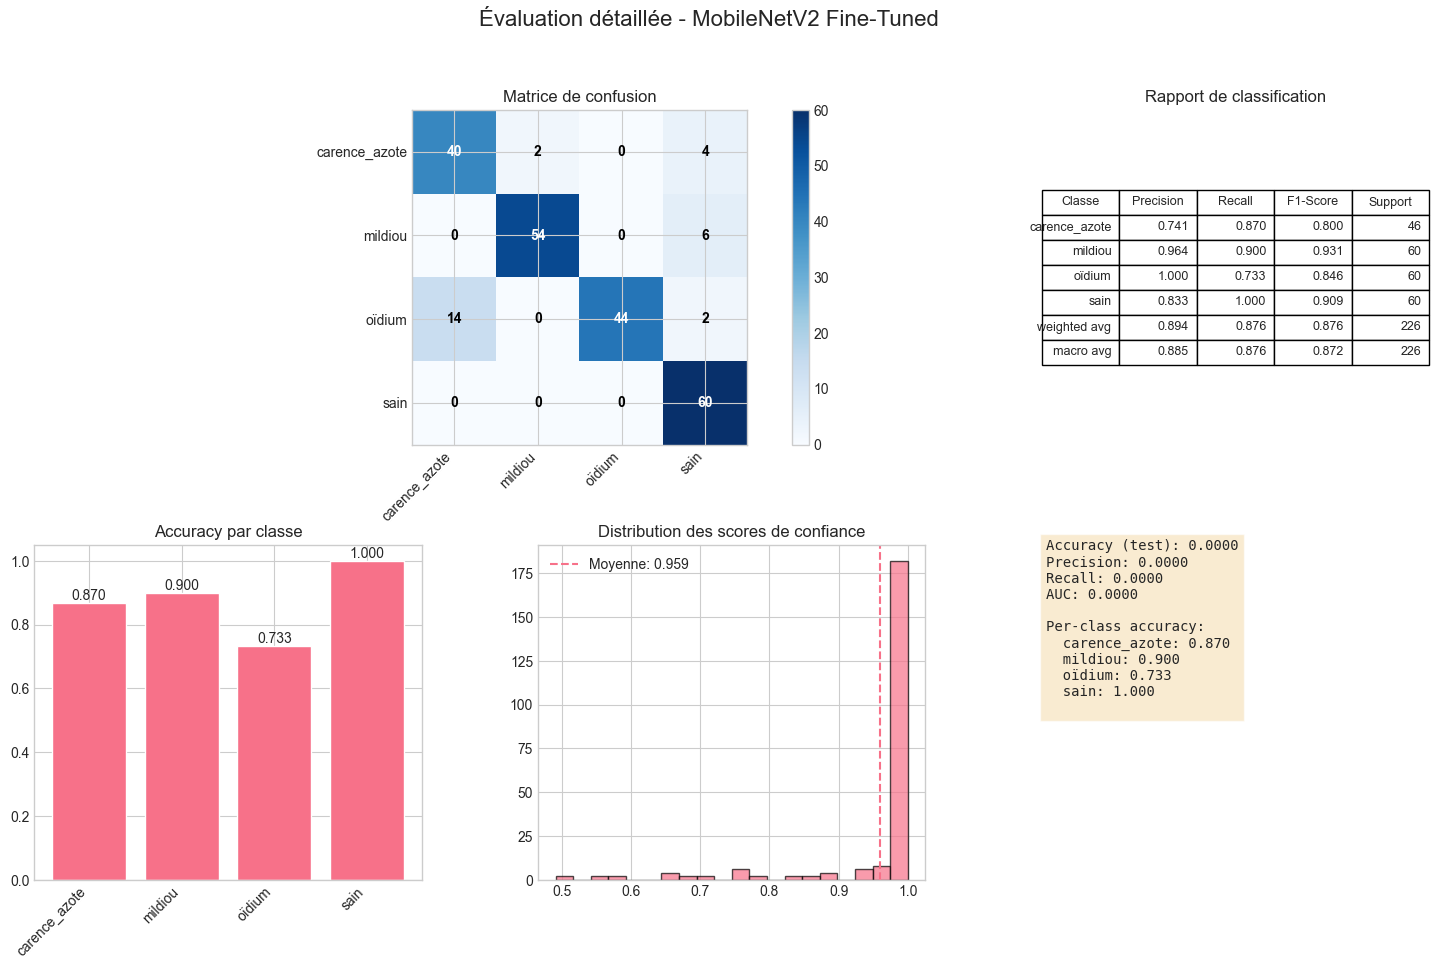

📸 Graphique sauvegardé: C:\Users\Ridha\Downloads\agripredict\agripredict\results\transfer_learning\evaluation_mobilenetv2_fine-tuned.png
ℹ️ Baseline non trouvé (optionnel).

📋 Comparaison:
       model accuracy precision recall      loss   auc
0   Baseline     None      None   None       NaN  None
1  FineTuned     None      None   None  0.594131  None

💾 Sauvegarde dans: C:\Users\Ridha\Downloads\agripredict\agripredict\backend\models\mobilenetv2_agripredict_20251207_212306
✅ Modèle sauvegardé: mobilenetv2_agripredict.keras
✅ Poids sauvegardés: mobilenetv2_agripredict.weights.h5
✅ Architecture sauvegardée: mobilenetv2_agripredict_architecture.json
✅ Historique sauvegardé: training_history.json
✅ Métriques sauvegardées: evaluation_metrics.json
✅ Rapport sauvegardé: final_report.txt

✅ Sauvegarde complète terminée.
ℹ️ Aucun fichier dans C:\Users\Ridha\Downloads\agripredict\agripredict\data\external_test. Ajoute des images et ré-exécute.

🎯 Script terminé - version finale prête.


In [ ]:
# ==================== VERSION FINALE CONSOLIDÉE DES SPRINTS 4 & 5 ====================
# Ce bloc représente une version consolidée et robuste qui combine les fonctionnalités
# essentielles des Sprints 4 et 5. Il inclut des améliorations de robustesse,
# une meilleure gestion des erreurs, et prépare le modèle pour la production.

# -------------------------
# Sprint 4/5 - Version finale
# -------------------------

# ==================== IMPORTATION DES LIBRAIRIES ESSENTIELLES ====================
# Importe un ensemble équilibré de librairies pour le transfer learning,
# l'évaluation et la préparation à la production.

# IMPORTS
import os
import json
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from datetime import datetime

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.preprocessing.image import ImageDataGenerator

from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.utils import class_weight

# ==================== CONFIGURATION DE L'ENVIRONNEMENT ====================
# Configure l'environnement pour un bon équilibre entre performance
# et stabilité, avec une gestion intelligente des ressources GPU.

# CONFIGURATION
warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("husl")

# TensorFlow performance hints (optionnel)
try:
    tf.config.optimizer.set_jit(True)
except Exception:
    pass

physical_devices = tf.config.list_physical_devices('GPU')
if physical_devices:
    try:
        tf.config.experimental.set_memory_growth(physical_devices[0], True)
        print(f"✅ GPU détecté: {physical_devices[0]}")
    except Exception:
        pass
else:
    print("⚠️  Aucun GPU détecté, utilisation du CPU")

# ==================== CONFIGURATION DE L'ARCHITECTURE DES DOSSIERS ====================
# Définit une structure de dossiers claire et complète qui supporte
# à la fois le développement, l'évaluation et le déploiement en production.

# -------------------------
# PATHS
# -------------------------
BASE_DIR = Path("..").resolve()         # ajuste si tu lances ailleurs
DATA_DIR = BASE_DIR / "data"
PROCESSED_DIR = DATA_DIR / "processed"
MODELS_DIR = BASE_DIR / "backend" / "models"
RESULTS_DIR = BASE_DIR / "results" / "transfer_learning"
PRODUCTION_DIR = BASE_DIR / "production_models"
EXTERNAL_TEST_DIR = DATA_DIR / "external_test"

# create folders if needed
for p in (MODELS_DIR, RESULTS_DIR, PRODUCTION_DIR, EXTERNAL_TEST_DIR):
    p.mkdir(parents=True, exist_ok=True)

print("📁 Chemins configurés:")
print(f"  BASE_DIR: {BASE_DIR}")
print(f"  PROCESSED_DIR: {PROCESSED_DIR}")
print(f"  MODELS_DIR: {MODELS_DIR}")
print(f"  RESULTS_DIR: {RESULTS_DIR}")
print(f"  PRODUCTION_DIR: {PRODUCTION_DIR}")
print(f"  EXTERNAL_TEST_DIR: {EXTERNAL_TEST_DIR}")

# ==================== FONCTIONS UTILITAIRES ROBUSTES ====================
# Définit des fonctions utilitaires avec gestion d'erreurs avancée pour
# garantir la stabilité du pipeline même en cas de problèmes de données.

# -------------------------
# UTIL: charger / réparer JSON (robuste)
# -------------------------
def load_json_safe(path, fallback=None, rewrite_if_corrupt=True):
    """
    Charge un JSON, et en cas de corruption crée un fallback (si fourni).
    """
    path = Path(path)
    if not path.exists():
        if fallback is not None:
            try:
                with open(path, 'w', encoding='utf-8') as f:
                    json.dump(fallback, f, indent=2, ensure_ascii=False)
                print(f"⚠️  JSON introuvable -> créé: {path}")
            except Exception as e:
                print(f"❌ Erreur création JSON: {e}")
        return fallback
    try:
        with open(path, 'r', encoding='utf-8') as f:
            return json.load(f)
    except json.JSONDecodeError:
        print(f"❌ JSON corrompu: {path}")
        if rewrite_if_corrupt and (fallback is not None):
            with open(path, 'w', encoding='utf-8') as f:
                json.dump(fallback, f, indent=2, ensure_ascii=False)
            print(f"✅ Remplacé par fallback: {path}")
            return fallback
        return fallback
    except Exception as e:
        print(f"❌ Erreur lecture JSON: {e}")
        return fallback

# ==================== CHARGEMENT ROBUSTE DES DONNÉES ====================
# Fonction améliorée pour charger les données avec une meilleure gestion
# des cas limites et des métadonnées manquantes.

# -------------------------
# CHARGER LES DONNÉES PRÉTRAITÉES
# -------------------------
def load_processed_dataset(processed_dir=PROCESSED_DIR):
    """
    Charge train/val/test (X.npy, y.npy) et metadata. Retourne dictionnaire dataset.
    """
    print("📥 Chargement des données prétraitées...")
    dataset = {'train': None, 'val': None, 'test': None, 'class_names': None, 'config': None}

    try:
        for split in ['train', 'val', 'test']:
            split_dir = Path(processed_dir) / split / 'numpy'
            if split_dir.exists():
                X = np.load(split_dir / 'X.npy')
                y = np.load(split_dir / 'y.npy')
                meta_path = split_dir / 'metadata.json'
                metadata = {}
                if meta_path.exists():
                    metadata = load_json_safe(meta_path, fallback={})
                dataset[split] = {'X': X, 'y': y, 'original_y': y.copy(), 'metadata': metadata}
                print(f"  ✅ {split.upper()}: {X.shape[0]} images")
                if split == 'train' and metadata.get('class_names'):
                    dataset['class_names'] = metadata['class_names']
            else:
                print(f"  ❌ {split.upper()}: Dossier non trouvé -> {split_dir}")

        # global config
        config_file = Path(processed_dir) / 'preprocessing_config.json'
        if config_file.exists():
            dataset['config'] = load_json_safe(config_file, fallback={})

        if all(dataset[s] is not None for s in ['train', 'val', 'test']):
            if dataset['class_names'] is None:
                # essayer depuis train metadata
                dataset['class_names'] = dataset['train']['metadata'].get('class_names', [])
            print("📊 Dataset chargé avec succès!")
            return dataset
        else:
            raise ValueError("Données incomplètes (train/val/test requises).")

    except Exception as e:
        print(f"❌ Erreur lors du chargement des données: {e}")
        return None

# ==================== EXÉCUTION DU CHARGEMENT DES DONNÉES ====================
# Charge le dataset avec des vérifications de robustesse et prépare
# les données pour l'entraînement et l'évaluation.

# Exécuter le chargement
dataset = load_processed_dataset()
if dataset is None:
    raise SystemExit("Arrêt: données prétraitées introuvables.")

# Extraire et préparer
X_train = dataset['train']['X']; y_train = dataset['train']['y']
X_val = dataset['val']['X']; y_val = dataset['val']['y']
X_test = dataset['test']['X']; y_test = dataset['test']['y']
class_names = dataset['class_names'] if dataset['class_names'] else [str(i) for i in np.unique(y_train)]
num_classes = len(class_names)

# one-hot
y_train_onehot = keras.utils.to_categorical(y_train, num_classes=num_classes)
y_val_onehot = keras.utils.to_categorical(y_val, num_classes=num_classes)
y_test_onehot = keras.utils.to_categorical(y_test, num_classes=num_classes)

# class weights (robuste)
try:
    cw = class_weight.compute_class_weight('balanced', classes=np.unique(y_train), y=y_train)
    class_weights = {i: float(w) for i, w in enumerate(cw)}
except Exception:
    class_weights = None

print(f"✅ Données prêtes: train={X_train.shape}, val={X_val.shape}, test={X_test.shape}, classes={class_names}")

# ==================== FONCTION D'ÉVALUATION COMPLÈTE ====================
# Version robuste de la fonction d'évaluation avec sauvegarde automatique
# des résultats et gestion des cas limites.

# -------------------------
# FONCTIONS D'ÉVALUATION & VISUALISATION
# -------------------------
def comprehensive_evaluation(model, X_test, y_test_onehot, class_names, model_name="Model"):
    """
    Évalue le modèle et produit:
      - metrics dict
      - graphiques sauvegardés dans RESULTS_DIR
    """
    print(f"\n🧪 ÉVALUATION - {model_name}")
    print("="*60)

    # prédictions
    y_pred_proba = model.predict(X_test, verbose=1)
    y_pred = np.argmax(y_pred_proba, axis=1)
    y_true = np.argmax(y_test_onehot, axis=1)

    # évaluer
    test_results = model.evaluate(X_test, y_test_onehot, verbose=0)
    metric_names = model.metrics_names
    test_metrics = dict(zip(metric_names, test_results))

    # classification report & confusion matrix
    report = classification_report(y_true, y_pred, target_names=class_names, output_dict=True)
    cm = confusion_matrix(y_true, y_pred)

    # plotting
    fig = plt.figure(figsize=(18,10))
    gs = fig.add_gridspec(2,3,hspace=0.3,wspace=0.3)

    # A: confusion matrix
    ax1 = fig.add_subplot(gs[0,:2])
    im = ax1.imshow(cm, interpolation='nearest', cmap='Blues')
    ax1.set_title('Matrice de confusion')
    tick_marks = np.arange(len(class_names))
    ax1.set_xticks(tick_marks); ax1.set_yticks(tick_marks)
    ax1.set_xticklabels(class_names, rotation=45, ha='right')
    ax1.set_yticklabels(class_names)
    thresh = cm.max() / 2.
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            color = "white" if cm[i,j] > thresh else "black"
            ax1.text(j, i, f"{cm[i,j]}", ha='center', va='center', color=color, fontweight='bold')
    plt.colorbar(im, ax=ax1)

    # B: classification report table
    ax2 = fig.add_subplot(gs[0,2])
    ax2.axis('off')
    table_data = []
    headers = ['Classe','Precision','Recall','F1-Score','Support']
    for cname in class_names:
        if cname in report:
            row = [cname,
                   f"{report[cname]['precision']:.3f}",
                   f"{report[cname]['recall']:.3f}",
                   f"{report[cname]['f1-score']:.3f}",
                   f"{int(report[cname]['support'])}"]
            table_data.append(row)
    for avg in ['weighted avg','macro avg']:
        if avg in report:
            row = [avg,
                   f"{report[avg]['precision']:.3f}",
                   f"{report[avg]['recall']:.3f}",
                   f"{report[avg]['f1-score']:.3f}",
                   f"{int(report[avg]['support'])}"]
            table_data.append(row)
    table = ax2.table(cellText=table_data, colLabels=headers, loc='center')
    table.auto_set_font_size(False); table.set_fontsize(9); table.scale(1,1.5)
    ax2.set_title('Rapport de classification')

    # C: accuracy par classe
    ax3 = fig.add_subplot(gs[1,0])
    class_accuracies = []
    for i in range(len(class_names)):
        idxs = (y_true == i)
        class_accuracies.append(float(np.sum(y_pred[idxs]==i) / np.sum(idxs)) if np.sum(idxs)>0 else 0.0)
    bars = ax3.bar(range(len(class_names)), class_accuracies)
    ax3.set_xticks(range(len(class_names)))
    ax3.set_xticklabels(class_names, rotation=45, ha='right')
    ax3.set_title('Accuracy par classe')
    for bar, val in zip(bars, class_accuracies):
        ax3.text(bar.get_x()+bar.get_width()/2., val, f"{val:.3f}", ha='center', va='bottom')

    # D: distribution confiance
    ax4 = fig.add_subplot(gs[1,1])
    confidence_scores = y_pred_proba[np.arange(len(y_pred_proba)), y_pred]
    ax4.hist(confidence_scores, bins=20, edgecolor='black', alpha=0.7)
    ax4.set_title('Distribution des scores de confiance')
    ax4.axvline(np.mean(confidence_scores), linestyle='--', label=f"Moyenne: {np.mean(confidence_scores):.3f}")
    ax4.legend()

    # E: résumé
    ax5 = fig.add_subplot(gs[1,2])
    ax5.axis('off')
    summary = (f"Accuracy (test): {test_metrics.get('accuracy',0):.4f}\n"
               f"Precision: {test_metrics.get('precision',0):.4f}\n"
               f"Recall: {test_metrics.get('recall',0):.4f}\n"
               f"AUC: {test_metrics.get('auc',0):.4f}\n\n")
    summary += "Per-class accuracy:\n"
    for cname, acc in zip(class_names, class_accuracies):
        summary += f"  {cname}: {acc:.3f}\n"
    ax5.text(0.01,0.5, summary, fontsize=10, family='monospace', bbox=dict(facecolor='wheat', alpha=0.6))

    plt.suptitle(f"Évaluation détaillée - {model_name}", fontsize=16)
    plt.tight_layout()
    save_path = RESULTS_DIR / f"evaluation_{model_name.replace(' ','_').lower()}.png"
    plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()
    print(f"📸 Graphique sauvegardé: {save_path}")

    out = {
        'test_metrics': test_metrics,
        'classification_report': report,
        'confusion_matrix': cm.tolist(),
        'class_accuracies': {class_names[i]: float(class_accuracies[i]) for i in range(len(class_names))},
        'confidence_scores_mean': float(np.mean(confidence_scores)),
        'confidence_scores_std': float(np.std(confidence_scores))
    }
    return out

# ==================== FONCTION DE SAUVEGARDE ROBUSTE ====================
# Version améliorée de la sauvegarde avec gestion d'erreurs complète
# et création de rapports structurés.

# -------------------------
# FONCTION: SAUVEGARDE ROBUSTE DU MODELE + MÉTRIQUES + RAPPORT
# -------------------------
def save_transfer_learning_model_fixed(model,
                                       history_frozen,
                                       history_finetune,
                                       evaluation_results,
                                       class_names,
                                       training_times,
                                       model_name="mobilenetv2_final"):
    """
    Sauvegarde complète et robuste du modèle et rapports.
    """
    from pathlib import Path
    model = model  # local alias
    timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
    model_dir = MODELS_DIR / f"{model_name}_{timestamp}"
    model_dir.mkdir(parents=True, exist_ok=True)

    print(f"\n💾 Sauvegarde dans: {model_dir}")

    # 1) modèle complet
    model_path = model_dir / f"{model_name}.keras"
    try:
        model.save(str(model_path))
        print(f"✅ Modèle sauvegardé: {model_path.name}")
    except Exception as e:
        print(f"❌ Erreur sauvegarde modèle: {e}")

    # 2) poids
    weights_path = model_dir / f"{model_name}.weights.h5"
    try:
        model.save_weights(str(weights_path))
        print(f"✅ Poids sauvegardés: {weights_path.name}")
    except Exception as e:
        print(f"❌ Erreur sauvegarde poids: {e}")

    # 3) architecture JSON
    architecture_path = model_dir / f"{model_name}_architecture.json"
    try:
        with open(architecture_path, 'w', encoding='utf-8') as f:
            f.write(model.to_json())
        print(f"✅ Architecture sauvegardée: {architecture_path.name}")
    except Exception as e:
        print(f"❌ Erreur architecture JSON: {e}")

    # 4) histories (sûr même si histories None)
    history_path = model_dir / "training_history.json"
    try:
        history_data = {}
        def extract_hist(h):
            if h is None:
                return {}
            return {k: v for k, v in h.history.items()}
        history_data['phase_1_frozen'] = extract_hist(history_frozen)
        history_data['phase_2_finetune'] = extract_hist(history_finetune)
        with open(history_path, 'w', encoding='utf-8') as f:
            json.dump(history_data, f, indent=2, ensure_ascii=False)
        print(f"✅ Historique sauvegardé: {history_path.name}")
    except Exception as e:
        print(f"❌ Erreur sauvegarde historique: {e}")

    # 5) ré-évaluation test (si possible)
    try:
        # s'assurer que X_test et y_test_onehot sont définis au scope global (chargés plus haut)
        test_results = model.evaluate(X_test, y_test_onehot, verbose=0)
        metric_names = model.metrics_names
        test_metrics = dict(zip(metric_names, test_results))
    except Exception as e:
        print(f"⚠️ Impossible d'évaluer (test set) : {e}")
        test_metrics = evaluation_results.get('test_metrics', {}) if evaluation_results else {}

    # 6) sauvegarde des métriques
    metrics_data = {
        'model_info': {
            'name': model_name,
            'timestamp': timestamp,
            'input_shape': model.input_shape[1:] if getattr(model, 'input_shape', None) else None,
            'num_classes': len(class_names),
            'total_params': int(model.count_params()) if hasattr(model, 'count_params') else None,
            'trainable_params': int(sum([tf.keras.backend.count_params(w) for w in model.trainable_weights])) if hasattr(model, 'trainable_weights') else None,
            'training_time_seconds': sum(training_times) if training_times else None
        },
        'class_names': class_names,
        'test_metrics': test_metrics,
        'evaluation_results_provided': bool(evaluation_results)
    }

    metrics_path = model_dir / "evaluation_metrics.json"
    try:
        with open(metrics_path, 'w', encoding='utf-8') as f:
            json.dump(metrics_data, f, indent=2, ensure_ascii=False)
        print(f"✅ Métriques sauvegardées: {metrics_path.name}")
    except Exception as e:
        print(f"❌ Erreur sauvegarde métriques: {e}")

    # 7) rapport textuel
    report_path = model_dir / "final_report.txt"
    try:
        acc = test_metrics.get('accuracy', None)
        report_lines = []
        report_lines.append("RAPPORT FINAL - Transfer Learning MobileNetV2")
        report_lines.append(f"Date: {datetime.now().isoformat()}")
        report_lines.append("")
        report_lines.append(f"Model dir: {model_dir}")
        report_lines.append(f"Classes: {class_names}")
        report_lines.append("")
        report_lines.append("Test metrics:")
        for k, v in test_metrics.items():
            report_lines.append(f" - {k}: {v}")
        if acc is not None:
            if acc >= 0.90:
                report_lines.append("Conclusion: EXCELLENT")
            elif acc >= 0.85:
                report_lines.append("Conclusion: TRÈS BON")
            elif acc >= 0.80:
                report_lines.append("Conclusion: BON")
            elif acc >= 0.70:
                report_lines.append("Conclusion: MOYEN")
            else:
                report_lines.append("Conclusion: À AMÉLIORER")
        with open(report_path, 'w', encoding='utf-8') as f:
            f.write("\n".join(str(x) for x in report_lines))
        print(f"✅ Rapport sauvegardé: {report_path.name}")
    except Exception as e:
        print(f"❌ Erreur sauvegarde rapport: {e}")

    return {
        'model_dir': model_dir,
        'model_path': model_path,
        'weights_path': weights_path,
        'metrics_path': metrics_path,
        'report_path': report_path,
        'test_metrics': test_metrics
    }

# ==================== FONCTION POUR TESTER SUR IMAGES EXTERNES ====================
# Permet de tester le modèle sur des images externes non vues pendant l'entraînement
# pour évaluer sa capacité de généralisation.

# -------------------------
# UTIL: charger images externes (avec dossier créé plus haut)
# -------------------------
def load_and_preprocess_external_images(image_dir=EXTERNAL_TEST_DIR, target_size=(224,224)):
    image_extensions = ['*.jpg','*.jpeg','*.png','*.JPG','*.JPEG','*.PNG']
    images = []
    image_paths = []
    for ext in image_extensions:
        for p in Path(image_dir).glob(ext):
            try:
                img = keras.preprocessing.image.load_img(p, target_size=target_size)
                arr = keras.preprocessing.image.img_to_array(img)
                arr = tf.keras.applications.mobilenet_v2.preprocess_input(arr)
                images.append(arr)
                image_paths.append(p)
            except Exception as e:
                print(f"❌ Erreur chargement {p}: {e}")
    if images:
        return np.array(images), image_paths
    else:
        return None, None

# ==================== SECTION D'EXÉCUTION PRINCIPALE ====================
# Cette section exécute les différentes étapes du pipeline avec des
# vérifications de sécurité pour éviter les erreurs en cas de données manquantes.

# -------------------------
# EXEMPLE D'UTILISATION (évaluer un modèle fine-tuné si présent)
# -------------------------
# NOTE: le notebook doit avoir défini model_finetune, history_frozen, history_finetune, time_frozen, time_finetune après entraînement.
# Protection si non définis:
if 'model_finetune' in globals():
    try:
        evaluation_finetune = comprehensive_evaluation(model_finetune, X_test, y_test_onehot, class_names, model_name="MobileNetV2 Fine-Tuned")
    except Exception as e:
        print(f"❌ Erreur évaluation modèle finetune: {e}")
        evaluation_finetune = {}
else:
    print("⚠️ model_finetune non défini dans ce scope. Skipping évaluation finetune.")
    evaluation_finetune = {}

# Charger baseline si présent
baseline_model = None
evaluation_baseline = {}
baseline_path = MODELS_DIR / 'baseline_model_complete.h5'
if baseline_path.exists():
    try:
        baseline_model = keras.models.load_model(str(baseline_path))
        evaluation_baseline = comprehensive_evaluation(baseline_model, X_test, y_test_onehot, class_names, model_name="CNN Baseline")
    except Exception as e:
        print(f"❌ Erreur chargement baseline: {e}")
else:
    print("ℹ️ Baseline non trouvé (optionnel).")

# ==================== COMPARAISON SIMPLIFIÉE DES MODÈLES ====================
# Fournit une comparaison rapide et lisible des performances entre
# différents modèles pour aider à la prise de décision.

# Comparaison succincte si possible
def compare_models_simple(evals, names):
    df = []
    keys = ['accuracy','precision','recall','loss','auc']
    for name, ev in zip(names, evals):
        row = {'model': name}
        for k in keys:
            row[k] = ev.get('test_metrics', {}).get(k, None) if ev else None
        df.append(row)
    df = pd.DataFrame(df)
    print("\n📋 Comparaison:")
    print(df)
    return df

if evaluation_finetune:
    compare_models_simple([evaluation_baseline, evaluation_finetune], ["Baseline","FineTuned"])

# ==================== SAUVEGARDE FINALE CONDITIONNELLE ====================
# Sauvegarde le modèle seulement si toutes les variables nécessaires
# sont disponibles, avec des messages d'erreur explicites sinon.

# -------------------------
# SAUVEGARDE FINALE (si variables prêtes)
# -------------------------
if ('model_finetune' in globals()) and ('history_frozen' in globals()) and ('history_finetune' in globals()) and ('time_frozen' in globals()) and ('time_finetune' in globals()):
    saved_files = save_transfer_learning_model_fixed(
        model=model_finetune,
        history_frozen=history_frozen,
        history_finetune=history_finetune,
        evaluation_results=evaluation_finetune,
        class_names=class_names,
        training_times=[time_frozen, time_finetune],
        model_name="mobilenetv2_agripredict"
    )
    print("\n✅ Sauvegarde complète terminée.")
else:
    print("\n⚠️ Variables d'entraînement non disponibles pour la sauvegarde complète.")
    print("   Assure-toi que les variables suivantes existent: model_finetune, history_frozen, history_finetune, time_frozen, time_finetune")

# ==================== TEST SUR IMAGES EXTERNES ====================
# Teste le modèle sur des images externes pour évaluer sa capacité
# de généralisation dans des conditions réelles.

# -------------------------
# TEST SUR IMAGES EXTERNES (exécutable même si pas d'entraînement)
# -------------------------
X_ext, paths_ext = load_and_preprocess_external_images(EXTERNAL_TEST_DIR)
if X_ext is not None and 'model_finetune' in globals():
    preds = model_finetune.predict(X_ext, verbose=1)
    classes = np.argmax(preds, axis=1)
    confidences = np.max(preds, axis=1)
    for p, c, conf in zip(paths_ext, classes, confidences):
        print(f"{p.name}: {class_names[c]} ({conf:.3f})")
else:
    if X_ext is None:
        print(f"ℹ️ Aucun fichier dans {EXTERNAL_TEST_DIR}. Ajoute des images et ré-exécute.")
    else:
        print("⚠️ model_finetune absent -> impossible de prédire sur images externes.")

# ==================== CONCLUSION ====================
# Message final indiquant que le script s'est exécuté avec succès.

# FIN
print("\n🎯 Script terminé - version finale prête.")